In [1]:
# CELL 1 — IMPORT LIBRARY
# Deskripsi: Import seluruh library yang dibutuhkan untuk
#            pipeline CNN feature extraction (ResNet50)
#            sebagai pengganti 15 fitur radiomik manual
# ============================================================

# --- Library standar Python ---
import os
import warnings
warnings.filterwarnings('ignore')

# --- Manipulasi data ---
import numpy as np
import pandas as pd

# --- Library khusus MRI ---
import nibabel as nib          # Membaca file .nii (NIfTI)

# --- Image processing untuk pipeline CNN ---
from PIL import Image           # Resize slice 2D ke (224,224)
import cv2                      # Alternatif resize + normalisasi intensitas

# --- Deep Learning: CNN Feature Extractor ---
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model

# --- Reduksi dimensi ---
from sklearn.decomposition import PCA

# --- Preprocessing & evaluasi (identik pipeline tabular) ---
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedKFold,
                                      cross_validate)
from sklearn.metrics import (accuracy_score, precision_score,
                               recall_score, f1_score,
                               roc_auc_score, confusion_matrix,
                               classification_report, roc_curve,
                               auc)

# --- Handling class imbalance ---
from imblearn.over_sampling import SMOTE

# --- Algoritma model (identik pipeline tabular & radiomik) ---
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier

# --- Visualisasi ---
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# --- Progress bar (penting: loop 60 pasien bisa lambat) ---
from tqdm import tqdm

# --- Export model ---
import joblib

# ── Konfigurasi tampilan ─────────────────────────────────────
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 120

# ── Konfigurasi GPU (opsional, aktif jika tersedia) ──────────
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"  GPU terdeteksi: {len(gpus)} unit — memory growth aktif")
    except RuntimeError as e:
        print(f"  GPU config error: {e}")
else:
    print("  Tidak ada GPU — berjalan di CPU (lebih lambat)")

# ── Verifikasi versi library ─────────────────────────────────
print("=" * 60)
print("   VERIFIKASI LIBRARY — 03_image_cnn.ipynb")
print("=" * 60)
print(f"  numpy         : {np.__version__}")
print(f"  pandas        : {pd.__version__}")
print(f"  nibabel       : {nib.__version__}")
print(f"  tensorflow    : {tf.__version__}")
print(f"  PIL (Pillow)  : {Image.__version__}")
print(f"  opencv        : {cv2.__version__}")

import sklearn
print(f"  scikit-learn  : {sklearn.__version__}")

import xgboost
print(f"  xgboost       : {xgboost.__version__}")

import imblearn
print(f"  imbalanced    : {imblearn.__version__}")

import tqdm as tqdm_lib
print(f"  tqdm          : {tqdm_lib.__version__}")

import matplotlib
print(f"  matplotlib    : {matplotlib.__version__}")
print(f"  seaborn       : {sns.__version__}")

  Tidak ada GPU — berjalan di CPU (lebih lambat)
   VERIFIKASI LIBRARY — 03_image_cnn.ipynb
  numpy         : 2.3.1
  pandas        : 2.3.1
  nibabel       : 5.4.2
  tensorflow    : 2.21.0
  PIL (Pillow)  : 11.3.0
  opencv        : 4.13.0
  scikit-learn  : 1.7.1
  xgboost       : 3.0.1
  imbalanced    : 0.14.1
  tqdm          : 4.68.2
  matplotlib    : 3.10.0
  seaborn       : 0.13.2


In [2]:
# CELL 2 — LOAD FILE EXCEL
# ============================================================

# ── Path dataset ─────────────────────────────────────────────
BASE_PATH  = r"Dataset_Citra"
EXCEL_PATH = BASE_PATH

FILE_PATIENT = os.path.join(EXCEL_PATH,
    "Supplementary Table 1 for patient info.xlsx")
FILE_SEQUENCE = os.path.join(EXCEL_PATH,
    "Supplementary Table 2 for  sequence parameters.xlsx")

# ── Validasi keberadaan file ──────────────────────────────────
print("=" * 60)
print("Section 1: Validasi Keberadaan File Excel")
print("=" * 60)

for label, path in [("Table Patient Info", FILE_PATIENT),
                      ("Table Sequence Parameters", FILE_SEQUENCE)]:
    status = "DITEMUKAN" if os.path.exists(path) else "TIDAK ADA"
    print(f"  {label}: {status}")
    print(f"          {path}")

# ── Load Supplementary Table 1 (info klinis pasien) ──────────
print("\nSection 2: Load Supplementary Table 1 — Info Pasien")
print("-" * 60)

df_patients = pd.read_excel(FILE_PATIENT, header =1)

# Normalisasi nama kolom: hapus spasi, lowercase
df_patients.columns = (df_patients.columns
                       .str.strip()
                       .str.lower()
                       .str.replace(' ', '_'))

print(f"  Shape       : {df_patients.shape}")
print(f"  Kolom       : {list(df_patients.columns)}")
print(f"\n  Preview (5 baris pertama):")
display(df_patients.head())

# ── Load Supplementary Table 2 (parameter sekuens MRI) ───────
print("\nSection 3: Load Supplementary Table 2 — Parameter Sekuens")
print("-" * 60)

df_sequences = pd.read_excel(FILE_SEQUENCE, header=1)
df_sequences.columns = (df_sequences.columns
                        .str.strip()
                        .str.lower()
                        .str.replace(' ', '_'))

print(f"  Shape       : {df_sequences.shape}")
print(f"  Kolom       : {list(df_sequences.columns)}")
print(f"\n  Preview (5 baris pertama):")
display(df_sequences.head())

# ── Identifikasi kolom EDSS untuk labeling ───────────────────
print("\nSection 4: Identifikasi Kolom EDSS")
print("-" * 60)

# Cari kolom yang mengandung kata 'edss' (case-insensitive)
edss_cols = [c for c in df_patients.columns if 'edss' in c]
print(f"  Kolom EDSS ditemukan : {edss_cols}")

if edss_cols:
    EDSS_COL = edss_cols[0]  # ambil kolom EDSS pertama
    print(f"  Kolom yang digunakan : '{EDSS_COL}'")
    print(f"\n  Statistik EDSS:")
    print(df_patients[EDSS_COL].describe().to_string())
    print(f"\n  Distribusi nilai EDSS:")
    print(df_patients[EDSS_COL].value_counts().sort_index().to_string())
else:
    print("  ⚠ Kolom EDSS tidak ditemukan! Cek nama kolom di atas.")

# ── Identifikasi kolom Patient ID ────────────────────────────
print("\nSection 5: Identifikasi Kolom Patient ID")
print("-" * 60)

id_candidates = [c for c in df_patients.columns
                 if any(kw in c for kw in ['patient', 'id', 'subject', 'no'])]
print(f"  Kandidat kolom ID    : {id_candidates}")

# ── Cek missing values di Table 1 ────────────────────────────
print("\nSection 6: Cek Missing Values")
print("-" * 60)

mv = df_patients.isnull().sum()
mv_nonzero = mv[mv > 0]
if len(mv_nonzero) == 0:
    print("  ✓ Tidak ada missing value di Table 1")
else:
    print(f"  ⚠ Missing value ditemukan:\n{mv_nonzero.to_string()}")
print("\n" + "=" * 60)
print("  Cell 2 selesai — Data Excel berhasil dimuat")
print("  Variabel aktif: df_patients, df_sequences, EDSS_COL")
print("=" * 60)
print("  Lanjut ke Cell 3 — Validasi File .nii + CNN Extraction")

Section 1: Validasi Keberadaan File Excel
  Table Patient Info: DITEMUKAN
          Dataset_Citra\Supplementary Table 1 for patient info.xlsx
  Table Sequence Parameters: DITEMUKAN
          Dataset_Citra\Supplementary Table 2 for  sequence parameters.xlsx

Section 2: Load Supplementary Table 1 — Info Pasien
------------------------------------------------------------
  Shape       : (60, 29)
  Kolom       : ['id', 'gender', 'age', 'age_of_onset', 'edss', 'does_the_time_difference_between_mri_acquisition_and_edss_<_two_months', 'types_of_medicines', 'presenting_symptom', 'dose_the_patient_has_co-moroidity', 'pyramidal', 'cerebella', 'brain_stem', 'sensory', 'sphincters', 'visual', 'mental', 'speech', 'motor_system', 'sensory_system', 'coordination', 'gait', 'bowel_and_bladder_function', 'mobility', 'mental_state', 'optic_discs', 'fields', 'nystagmus', 'ocular_movement', 'swallowing']

  Preview (5 baris pertama):


,id,gender,age,age_of_onset,edss,does_the_time_difference_between_mri_acquisition_and_edss_<_two_months,types_of_medicines,presenting_symptom,dose_the_patient_has_co-moroidity,pyramidal,cerebella,brain_stem,sensory,sphincters,visual,mental,speech,motor_system,sensory_system,coordination,gait,bowel_and_bladder_function,mobility,mental_state,optic_discs,fields,nystagmus,ocular_movement,swallowing
0,1,F,56,43,3.0000,No,Gelenia,Motor,No,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,1,0,0
1,2,F,29,19,1.5000,No,Gelenia,Sensory,No,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0
2,3,F,15,8,4.0000,No,Tysabri,Motor,No,1,1,0,0,0,1,0,0,1,0,1,0,0,0,0,1,0,0,0,0
3,4,F,24,20,6.0000,No,Tysabri,Sensory,No,1,1,1,0,1,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0
4,5,F,33,31,0.0000,No,Avonex,Pain,No,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0



Section 3: Load Supplementary Table 2 — Parameter Sekuens
------------------------------------------------------------
  Shape       : (60, 13)
  Kolom       : ['id', 'repetition_time__(tr)', 'echo_time_(te)', 'slice_thickness', 'spacing_between_slices', 'repetition_time__(tr).1', 'echo_time_(te).1', 'slice_thickness_.1', 'spacing_between_slices.1', 'repetition_time__(tr).2', 'echo_time_(te).2', 'slice_thickness_.2', 'spacing_between_slices.2']

  Preview (5 baris pertama):


,id,repetition_time__(tr),echo_time_(te),slice_thickness,spacing_between_slices,repetition_time__(tr).1,echo_time_(te).1,slice_thickness_.1,spacing_between_slices.1,repetition_time__(tr).2,echo_time_(te).2,slice_thickness_.2,spacing_between_slices.2
0,1,8500,106.0000,5.0000,5.5000,400.0000,8.7000,5.0000,6.5000,400.0000,8.7000,5.0000,6.5000
1,2,9000,82.0000,5.0000,6.7500,305.0000,4.7600,5.0000,6.5000,305.0000,4.7600,5.0000,6.5000
2,3,9000,82.0000,5.0000,6.5000,305.0000,4.7600,5.0000,6.5000,305.0000,4.7600,5.0000,6.5000
3,4,6000,106.0000,5.0000,5.5000,400.0000,8.7000,5.0000,6.5000,400.0000,8.7000,5.0000,6.5000
4,5,5200,106.0000,5.0000,5.5000,550.0000,8.7000,5.0000,5.5000,550.0000,8.7000,5.0000,5.5000



Section 4: Identifikasi Kolom EDSS
------------------------------------------------------------
  Kolom EDSS ditemukan : ['edss', 'does_the_time_difference_between_mri_acquisition_and_edss_<_two_months']
  Kolom yang digunakan : 'edss'

  Statistik EDSS:
count   60.0000
mean     2.2667
std      1.5957
min      0.0000
25%      1.0000
50%      2.0000
75%      3.5000
max      6.0000

  Distribusi nilai EDSS:
edss
0.0000     5
0.5000     4
1.0000    13
1.5000     7
2.0000     4
2.5000     2
3.0000     8
3.5000     4
4.0000     7
4.5000     1
5.0000     3
6.0000     2

Section 5: Identifikasi Kolom Patient ID
------------------------------------------------------------
  Kandidat kolom ID    : ['id', 'dose_the_patient_has_co-moroidity', 'pyramidal']

Section 6: Cek Missing Values
------------------------------------------------------------
  ✓ Tidak ada missing value di Table 1

  Cell 2 selesai — Data Excel berhasil dimuat
  Variabel aktif: df_patients, df_sequences, EDSS_COL
  Lanjut ke 

In [3]:
# Cek cepat — jalankan di cell terpisah, tidak perlu disimpan
print("Kolom ID contoh isi:")
print(df_patients['id'].head(10).to_string())
print("\nTotal pasien:", df_patients['id'].nunique())
print("\nFormat ID:", df_patients['id'].iloc[0])

Kolom ID contoh isi:
0     1
1     2
2     3
3     4
4     5
5     6
6     7
7     8
8     9
9    10

Total pasien: 60

Format ID: 1


In [4]:
# CELL 3 — VALIDASI FILE .nii + CNN FEATURE EXTRACTION
# Deskripsi: Validasi kelengkapan file .nii (FLAIR, T1, T2),
#            ekstraksi fitur ResNet50 per pasien via
#            multi-slice averaging, simpan hasil ke CSV cache.
#            LesionSeg TIDAK dipakai (tidak relevan untuk CNN)
# ============================================================

# ── Konfigurasi path & parameter ─────────────────────────────
PATIENT_DIR  = BASE_PATH          # folder induk berisi Patient-1 dst
CACHE_PATH   = "ConfigdanOutputCNN/cnn_features_resnet50.csv"  # hasil ekstraksi disimpan di sini
N_PATIENTS   = 60
N_SLICES     = 5    # jumlah slice tengah yang diambil per sekuens
IMG_SIZE     = (224, 224)

# Sekuens yang dipakai (tanpa LesionSeg)
def get_sequences(pid):
    """Nama file mengikuti nomor pasien: Patient-2 → 2-Flair.nii dst."""
    return {
        'flair': f'{pid}-Flair.nii',
        't1'   : f'{pid}-T1.nii',
        't2'   : f'{pid}-T2.nii',
    }

# ── Section 1: Bangun ResNet50 Feature Extractor ─────────────
print("=" * 60)
print("Section 1: Inisialisasi ResNet50 Feature Extractor")
print("=" * 60)

# Load ResNet50 tanpa fully-connected layer (include_top=False)
# pooling='avg' → Global Average Pooling otomatis → output (2048,)
base_model = ResNet50(
    weights    = 'imagenet',
    include_top = False,
    pooling    = 'avg',
    input_shape = (IMG_SIZE[0], IMG_SIZE[1], 3)
)
base_model.trainable = False  # freeze semua layer — hanya inference

feature_extractor = base_model  # alias lebih deskriptif

print(f"  Model     : ResNet50 (imagenet weights, frozen)")
print(f"  Input     : {IMG_SIZE} × 3 channel (pseudo-RGB)")
print(f"  Output    : (2048,) per sekuens via Global Avg Pooling")
print(f"  Trainable : {base_model.trainable} (pure feature extractor)")
print(f"  Total params: {base_model.count_params():,}")

# ── Section 2: Fungsi Helper ──────────────────────────────────
print("\nSection 2: Definisi Fungsi Helper")
print("-" * 60)

def load_nii_volume(path):
    """Load volume 3D dari file .nii, return numpy array float32."""
    img  = nib.load(path)
    data = img.get_fdata(dtype=np.float32)
    # Pastikan orientasi: (H, W, D) — depth/slice di axis terakhir
    if data.ndim == 4:
        data = data[..., 0]   # ambil timepoint pertama jika ada
    return data

def normalize_slice(slice_2d):
    """
    Normalisasi intensitas slice MRI ke [0, 255] uint8.
    MRI memiliki arbitrary intensity range — wajib dinormalisasi
    sebelum masuk ResNet50 yang mengharapkan input seperti foto.
    """
    mn, mx = slice_2d.min(), slice_2d.max()
    if mx - mn < 1e-8:       # slice kosong / semua nilai sama
        return np.zeros((*slice_2d.shape, 3), dtype=np.uint8)
    normalized = (slice_2d - mn) / (mx - mn) * 255.0
    uint8_slice = normalized.astype(np.uint8)
    # Grayscale → pseudo-RGB (replikasi ke 3 channel)
    return np.stack([uint8_slice] * 3, axis=-1)

def extract_features_from_volume(volume, n_slices=N_SLICES):
    """
    Ambil n_slices slice axial di sekitar tengah volume,
    resize ke (224,224), ekstrak fitur ResNet50,
    lalu rata-rata → satu vektor (2048,) per sekuens.
    """
    depth      = volume.shape[2]
    mid        = depth // 2
    half       = n_slices // 2
    slice_idxs = range(max(0, mid - half),
                        min(depth, mid + half + 1))

    slice_features = []
    for idx in slice_idxs:
        s   = volume[:, :, idx]              # ambil slice 2D (H × W)
        rgb = normalize_slice(s)             # → (H, W, 3) uint8

        # Resize ke (224, 224) menggunakan PIL
        pil_img  = Image.fromarray(rgb).resize(
            IMG_SIZE, Image.BILINEAR)
        arr      = np.array(pil_img, dtype=np.float32)  # (224,224,3)

        # preprocess_input: normalisasi sesuai standar ImageNet ResNet50
        arr      = preprocess_input(arr[np.newaxis, ...])  # (1,224,224,3)

        # Forward pass → (1, 2048)
        feat     = feature_extractor.predict(arr, verbose=0)
        slice_features.append(feat[0])

    # Average pooling lintas slice → (2048,)
    return np.mean(slice_features, axis=0)

print("  Fungsi helper terdefinisi:")
print("    load_nii_volume()             — load file .nii")
print("    normalize_slice()             — normalisasi intensitas MRI")
print("    extract_features_from_volume() — ResNet50 + avg pooling")

# ── Section 3: Validasi Kelengkapan File .nii ─────────────────
print("\nSection 3: Validasi Kelengkapan File .nii")
print("-" * 60)

missing_files = []
valid_patients = []

for pid in range(1, N_PATIENTS + 1):
    patient_folder = os.path.join(PATIENT_DIR, f"Patient-{pid}")
    patient_ok     = True

    if not os.path.isdir(patient_folder):
        missing_files.append(f"Patient-{pid}: FOLDER TIDAK ADA")
        patient_ok = False
        continue

    for seq_name, fname in get_sequences(pid).items():
        fpath = os.path.join(patient_folder, fname)
        if not os.path.exists(fpath):
            missing_files.append(f"Patient-{pid}/{fname}: TIDAK ADA")
            patient_ok = False

    if patient_ok:
        valid_patients.append(pid)

if missing_files:
    print(f"  ⚠ File tidak lengkap ({len(missing_files)} item):")
    for m in missing_files:
        print(f"    - {m}")
else:
    print(f"  ✓ Semua file lengkap — {len(valid_patients)}/60 pasien valid")

print(f"  Pasien yang akan diproses: {len(valid_patients)}")

# ── Section 4: CNN Feature Extraction (dengan cache check) ────
print("\nSection 4: CNN Feature Extraction")
print("-" * 60)

# Cek apakah cache sudah ada — skip ekstraksi jika ada
if os.path.exists(CACHE_PATH):
    print(f"  ✓ Cache ditemukan: '{CACHE_PATH}'")
    print(f"  → Load dari cache (skip ekstraksi ulang)")
    df_raw_features = pd.read_csv(CACHE_PATH, index_col='patient_id')
    print(f"  Shape dari cache: {df_raw_features.shape}")

else:
    print(f"  Cache belum ada — mulai ekstraksi ResNet50...")
    print(f"  Parameter: {N_SLICES} slice tengah, resize {IMG_SIZE}")
    print(f"  Estimasi waktu (CPU): ~15–30 menit\n")

    all_features = {}   # {patient_id: np.array (6144,)}
    failed       = []   # pasien yang gagal diproses

    for pid in tqdm(valid_patients, desc="Ekstraksi pasien", unit="pasien"):
        patient_folder = os.path.join(PATIENT_DIR, f"Patient-{pid}")
        seq_vectors    = []

        try:
            for seq_name, fname in get_sequences(pid).items():
                fpath  = os.path.join(patient_folder, fname)
                volume = load_nii_volume(fpath)         # (H,W,D)
                feat   = extract_features_from_volume(volume)  # (2048,)
                seq_vectors.append(feat)

            # Gabung 3 sekuens → (6144,)
            combined = np.concatenate(seq_vectors)     # (6144,)
            all_features[pid] = combined

        except Exception as e:
            failed.append((pid, str(e)))
            print(f"\n  ⚠ Patient-{pid} gagal: {e}")

    # Buat DataFrame dari hasil ekstraksi
    feature_cols   = ([f"flair_{i}" for i in range(2048)] +
                      [f"t1_{i}"    for i in range(2048)] +
                      [f"t2_{i}"    for i in range(2048)])

    df_raw_features = pd.DataFrame.from_dict(
        all_features, orient='index', columns=feature_cols)
    df_raw_features.index.name = 'patient_id'

    # Simpan ke CSV sebagai cache
    df_raw_features.to_csv(CACHE_PATH)
    print(f"\n  ✓ Ekstraksi selesai!")
    print(f"  Cache disimpan: '{CACHE_PATH}'")

    if failed:
        print(f"  ⚠ Pasien gagal ({len(failed)}): {[f[0] for f in failed]}")

# ── Section 5: Ringkasan Hasil Ekstraksi ──────────────────────
print("\nSection 5: Ringkasan Hasil Ekstraksi")
print("-" * 60)
print(f"  Shape df_raw_features : {df_raw_features.shape}")
print(f"  → {df_raw_features.shape[0]} pasien × {df_raw_features.shape[1]} fitur")
print(f"  Breakdown fitur:")
print(f"    FLAIR : 2048 dimensi (indeks 0–2047)")
print(f"    T1    : 2048 dimensi (indeks 2048–4095)")
print(f"    T2    : 2048 dimensi (indeks 4096–6143)")
print(f"  Missing values: {df_raw_features.isnull().sum().sum()}")
print(f"  Rentang nilai : [{df_raw_features.values.min():.4f}, "
      f"{df_raw_features.values.max():.4f}]")

print("\n" + "=" * 60)
print("  Cell 3 selesai — Fitur CNN (6144,) tersimpan")
print("  Variabel aktif: df_raw_features, feature_extractor")
print("=" * 60)
print("  Lanjut ke Cell 4 — PCA Reduksi Dimensi")

Section 1: Inisialisasi ResNet50 Feature Extractor
  Model     : ResNet50 (imagenet weights, frozen)
  Input     : (224, 224) × 3 channel (pseudo-RGB)
  Output    : (2048,) per sekuens via Global Avg Pooling
  Trainable : False (pure feature extractor)
  Total params: 23,587,712

Section 2: Definisi Fungsi Helper
------------------------------------------------------------
  Fungsi helper terdefinisi:
    load_nii_volume()             — load file .nii
    normalize_slice()             — normalisasi intensitas MRI
    extract_features_from_volume() — ResNet50 + avg pooling

Section 3: Validasi Kelengkapan File .nii
------------------------------------------------------------
  ✓ Semua file lengkap — 60/60 pasien valid
  Pasien yang akan diproses: 60

Section 4: CNN Feature Extraction
------------------------------------------------------------
  Cache belum ada — mulai ekstraksi ResNet50...
  Parameter: 5 slice tengah, resize (224, 224)
  Estimasi waktu (CPU): ~15–30 menit



Ekstraksi pasien: 100%|██████████| 60/60 [06:35<00:00,  6.60s/pasien]



  ✓ Ekstraksi selesai!
  Cache disimpan: 'ConfigdanOutputCNN/cnn_features_resnet50.csv'

Section 5: Ringkasan Hasil Ekstraksi
------------------------------------------------------------
  Shape df_raw_features : (60, 6144)
  → 60 pasien × 6144 fitur
  Breakdown fitur:
    FLAIR : 2048 dimensi (indeks 0–2047)
    T1    : 2048 dimensi (indeks 2048–4095)
    T2    : 2048 dimensi (indeks 4096–6143)
  Missing values: 0
  Rentang nilai : [0.0000, 12.9232]

  Cell 3 selesai — Fitur CNN (6144,) tersimpan
  Variabel aktif: df_raw_features, feature_extractor
  Lanjut ke Cell 4 — PCA Reduksi Dimensi


Section 1: Standarisasi Fitur Sebelum PCA
  Input shape      : (60, 6144)
  Setelah scaling  : mean≈0, std≈1 per fitur
  Shape X_scaled   : (60, 6144)

Section 2: Fit PCA & Tentukan n_components Optimal
------------------------------------------------------------
  Total komponen maksimum : 60
  Threshold variance      : 95%
  n_components optimal    : 47
  Variance tercakup       : 95.48%
  Reduksi dimensi         : 6144 → 47 (99.2% dikurangi)

  Top-10 komponen PCA (variance per komponen):
  PC      Var Ratio   Cumulative
  ------------------------------
  PC1       0.1113      0.1113
  PC2       0.0833      0.1945
  PC3       0.0726      0.2672
  PC4       0.0509      0.3181
  PC5       0.0462      0.3643
  PC6       0.0416      0.4059
  PC7       0.0356      0.4415
  PC8       0.0316      0.4731
  PC9       0.0306      0.5037
  PC10      0.0280      0.5316

Section 3: Scree Plot
------------------------------------------------------------


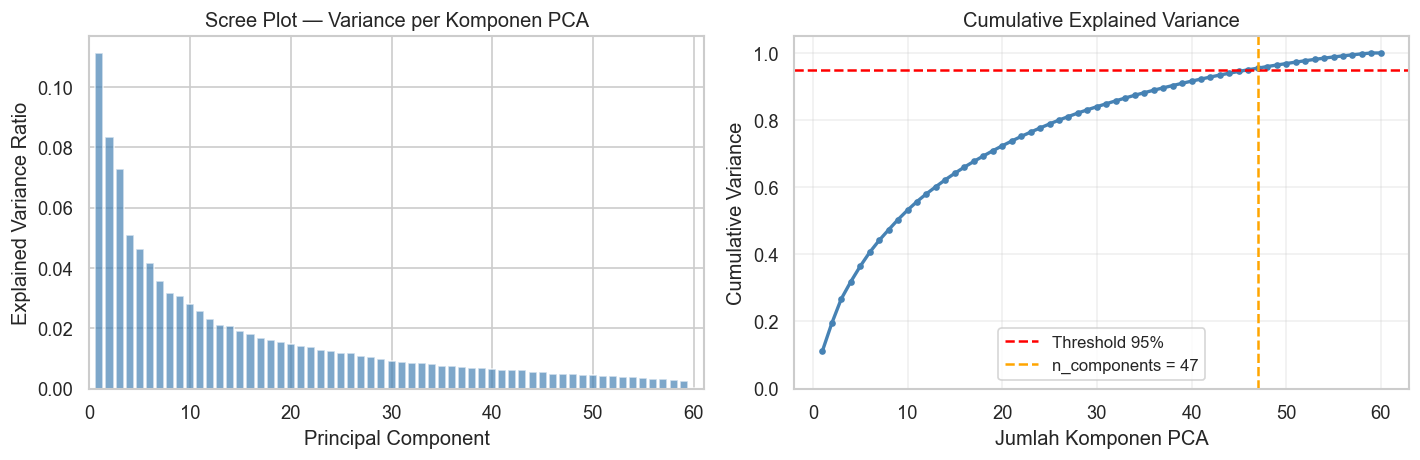

  Plot disimpan: 'ConfigdanOutputCNN/pca_scree_plot.png'

Section 4: Transform Data ke Ruang PCA Optimal
------------------------------------------------------------
  Shape df_cnn_features   : (60, 47)
  Kolom                   : PC1 s/d PC47
  Variance tercakup       : 95.47%

  Preview (5 baris pertama):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,PC37,PC38,PC39,PC40,PC41,PC42,PC43,PC44,PC45,PC46,PC47
patient_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,35.3849,-31.9125,-15.3892,37.7833,-31.2678,6.1139,-10.7587,16.8293,-30.7228,-2.3438,20.9945,-4.6032,-4.1707,-27.5177,8.8700,11.2517,31.2165,9.7836,8.8884,-12.4951,11.4984,26.6359,-7.8334,-0.6849,7.2963,-6.8343,8.0581,0.9960,-6.4160,0.1303,-5.4479,1.2364,-1.6806,-1.0161,1.3380,2.3863,1.8426,-1.5737,0.0403,-1.7064,0.1279,0.4275,0.6512,-1.7295,-0.0772,-2.1938,0.2661
2,-18.3863,35.7826,-2.8194,-2.3680,-11.5834,-10.3115,1.1358,-11.9574,7.9723,-2.2496,9.3760,4.4395,2.8277,-6.9547,-13.7974,0.4726,-2.3444,9.1933,-1.4271,-11.2971,3.2696,-0.6732,-5.2551,3.6215,11.2504,4.6570,-3.3868,-4.7129,4.7109,1.2456,4.3882,-13.0884,-7.0968,6.7796,8.3355,0.5853,2.9349,-5.0310,-1.5695,-0.3560,-1.8640,0.8583,5.1928,16.8936,-4.8058,2.1828,-1.3986
3,-22.7022,40.2825,-1.5056,16.2610,-2.8439,-1.7248,16.3364,-3.2014,4.8004,3.8552,-8.6640,-3.9334,-2.3603,-4.2338,-11.9766,-7.2000,1.0198,2.5425,-8.0621,-12.3722,-7.4569,-1.0681,-9.6384,-1.9779,1.7258,1.0587,2.1564,9.4318,1.8946,-5.9508,-5.3300,-10.3795,-14.6978,0.2490,5.6436,5.1305,3.7547,6.2807,-3.4939,13.7151,-12.2088,-1.1120,3.0548,-6.8420,-16.6536,-4.4960,5.2693
4,-17.4076,8.8041,-19.9926,-1.0042,9.0125,0.7245,-16.8578,-6.7449,-0.0112,-8.8971,-0.0358,-16.5406,-3.0944,-3.7030,-3.8546,-6.0280,1.1972,0.3531,-1.6765,2.9953,0.0370,-5.1722,-10.1763,0.6062,-1.5525,13.8199,-4.3310,-2.6198,-20.8389,1.9484,-0.8916,5.0024,3.3257,2.7108,7.3934,-6.1362,-4.2369,-8.4349,-1.4507,-8.9408,0.6928,-9.0304,3.0473,-3.0205,-5.3587,5.5092,2.4967
5,-20.1414,5.1223,-17.7570,-8.9684,-1.6259,11.0055,-7.4239,-6.1316,-15.7902,-3.3601,-1.2424,5.6325,-2.2849,12.5131,-3.9905,4.0649,3.1145,0.9698,-1.6263,-2.9515,2.7071,-1.8333,12.2894,1.5600,3.5224,-8.4224,4.8323,-3.9285,0.4589,-2.3349,-1.2818,-2.8429,-3.2242,-6.7788,-1.4907,-0.4742,0.8604,1.4328,6.0369,5.1837,-10.2270,1.7506,1.5892,2.1694,3.0329,2.0979,-2.6476



  Cache PCA disimpan: 'ConfigdanOutputCNN/cnn_features_pca.csv'

  Cell 4 selesai — df_cnn_features siap untuk modeling
  Variabel aktif: df_cnn_features, pca_final, scaler_pca
  Lanjut ke Cell 5 — Label EDSS + Class Imbalance


In [6]:
# CELL 4 — PCA REDUKSI DIMENSI
# Deskripsi: Mereduksi 6144 fitur CNN menjadi n_components
#            optimal berdasarkan threshold explained_variance
#            ≥ 95%. Output: df_cnn_features siap untuk modeling.
# ============================================================

# ── Konfigurasi ──────────────────────────────────────────────
PCA_VARIANCE_THRESHOLD = 0.95   # pertahankan 95% informasi
PCA_CACHE_PATH = "ConfigdanOutputCNN/cnn_features_pca.csv"

# ── Section 1: Standarisasi Sebelum PCA ──────────────────────
print("=" * 60)
print("Section 1: Standarisasi Fitur Sebelum PCA")
print("=" * 60)

# PCA sensitif terhadap skala — wajib StandardScaler dulu
# Fit di seluruh data (bukan train saja) karena PCA di sini
# hanya untuk reduksi representasi, bukan data leakage dalam CV
scaler_pca = StandardScaler()
X_scaled   = scaler_pca.fit_transform(df_raw_features.values)

print(f"  Input shape      : {df_raw_features.shape}")
print(f"  Setelah scaling  : mean≈0, std≈1 per fitur")
print(f"  Shape X_scaled   : {X_scaled.shape}")

# ── Section 2: Fit PCA & Tentukan n_components Optimal ───────
print("\nSection 2: Fit PCA & Tentukan n_components Optimal")
print("-" * 60)

# Fit PCA dengan semua komponen dulu untuk melihat kurva variance
# n_components dibatasi min(n_samples, n_features) = min(60, 6144) = 60
pca_full = PCA(n_components=None, random_state=42)
pca_full.fit(X_scaled)

cumvar = np.cumsum(pca_full.explained_variance_ratio_)

# Temukan n_components minimum yang mencapai threshold
n_components_optimal = np.argmax(cumvar >= PCA_VARIANCE_THRESHOLD) + 1

print(f"  Total komponen maksimum : {len(cumvar)}")
print(f"  Threshold variance      : {PCA_VARIANCE_THRESHOLD*100:.0f}%")
print(f"  n_components optimal    : {n_components_optimal}")
print(f"  Variance tercakup       : {cumvar[n_components_optimal-1]*100:.2f}%")
print(f"  Reduksi dimensi         : 6144 → {n_components_optimal} "
      f"({(1 - n_components_optimal/6144)*100:.1f}% dikurangi)")

# Tabel top-10 komponen pertama
print(f"\n  Top-10 komponen PCA (variance per komponen):")
print(f"  {'PC':<6} {'Var Ratio':>10} {'Cumulative':>12}")
print(f"  {'-'*30}")
for i in range(min(10, len(cumvar))):
    print(f"  PC{i+1:<4} {pca_full.explained_variance_ratio_[i]:>9.4f}"
          f"  {cumvar[i]:>10.4f}")

# ── Section 3: Scree Plot untuk Laporan Skripsi ───────────────
print("\nSection 3: Scree Plot")
print("-" * 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot kiri — Scree plot (variance per komponen)
axes[0].bar(range(1, len(cumvar) + 1),
            pca_full.explained_variance_ratio_,
            color='steelblue', alpha=0.7, edgecolor='white')
axes[0].set_title('Scree Plot — Variance per Komponen PCA', fontsize=12)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_xlim([0, len(cumvar) + 1])

# Plot kanan — Cumulative variance dengan garis threshold
axes[1].plot(range(1, len(cumvar) + 1), cumvar,
             marker='o', markersize=3, color='steelblue', linewidth=2)
axes[1].axhline(y=PCA_VARIANCE_THRESHOLD, color='red',
                linestyle='--', linewidth=1.5,
                label=f'Threshold {PCA_VARIANCE_THRESHOLD*100:.0f}%')
axes[1].axvline(x=n_components_optimal, color='orange',
                linestyle='--', linewidth=1.5,
                label=f'n_components = {n_components_optimal}')
axes[1].set_title('Cumulative Explained Variance', fontsize=12)
axes[1].set_xlabel('Jumlah Komponen PCA')
axes[1].set_ylabel('Cumulative Variance')
axes[1].set_ylim([0, 1.05])
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNN/pca_scree_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Plot disimpan: 'ConfigdanOutputCNN/pca_scree_plot.png'")

# ── Section 4: Transform dengan n_components Optimal ─────────
print("\nSection 4: Transform Data ke Ruang PCA Optimal")
print("-" * 60)

# Fit ulang PCA dengan n_components yang sudah ditentukan
pca_final = PCA(n_components=n_components_optimal, random_state=42)
X_pca     = pca_final.fit_transform(X_scaled)   # (60, n_components)

# Buat DataFrame final dengan nama kolom PC1, PC2, ... PCn
pca_cols       = [f"PC{i+1}" for i in range(n_components_optimal)]
df_cnn_features = pd.DataFrame(
    X_pca,
    index   = df_raw_features.index,   # pertahankan patient_id
    columns = pca_cols
)

print(f"  Shape df_cnn_features   : {df_cnn_features.shape}")
print(f"  Kolom                   : PC1 s/d PC{n_components_optimal}")
print(f"  Variance tercakup       : {pca_final.explained_variance_ratio_.sum()*100:.2f}%")
print(f"\n  Preview (5 baris pertama):")
display(df_cnn_features.head())

# Simpan ke CSV sebagai cache
df_cnn_features.to_csv(PCA_CACHE_PATH)
print(f"\n  Cache PCA disimpan: '{PCA_CACHE_PATH}'")

print("\n" + "=" * 60)
print("  Cell 4 selesai — df_cnn_features siap untuk modeling")
print("  Variabel aktif: df_cnn_features, pca_final, scaler_pca")
print("=" * 60)
print("  Lanjut ke Cell 5 — Label EDSS + Class Imbalance")

In [7]:
# CELL 5 — LABEL EDSS + PENANGANAN CLASS IMBALANCE
# Deskripsi: Konversi EDSS ke label biner, gabungkan dengan
#            df_cnn_features, tangani imbalance dengan SMOTE.
#            Logika identik dengan pipeline radiomik manual
#            agar hasil komparatif antar eksperimen valid.
# ============================================================

# ── Section 1: Mapping Label EDSS → Biner ────────────────────
print("=" * 60)
print("Section 1: Mapping Label EDSS ke Biner")
print("=" * 60)

# Aturan labeling (identik radiomik manual):
# EDSS < 3  → Mild (0)
# EDSS >= 3 → Moderate-Severe (1)
df_label = df_patients[['id', EDSS_COL]].copy()
df_label['label'] = (df_label[EDSS_COL] >= 3).astype(int)
df_label['label_str'] = df_label['label'].map(
    {0: 'Mild', 1: 'Moderate-Severe'})

print(f"  Aturan labeling:")
print(f"    EDSS < 3  → Mild (0)")
print(f"    EDSS >= 3 → Moderate-Severe (1)")
print(f"\n  Distribusi label:")

label_counts = df_label['label'].value_counts().sort_index()
for lbl, cnt in label_counts.items():
    name = 'Mild' if lbl == 0 else 'Moderate-Severe'
    pct  = cnt / len(df_label) * 100
    bar  = '█' * int(pct / 2)
    print(f"    Kelas {lbl} ({name:<17}): {cnt:>2} pasien "
          f"({pct:.1f}%) {bar}")

imbalance_ratio = label_counts.max() / label_counts.min()
print(f"\n  Imbalance ratio : {imbalance_ratio:.2f}:1")
if imbalance_ratio > 1.5:
    print(f"  → Class imbalance terdeteksi, SMOTE diperlukan")
else:
    print(f"  → Distribusi relatif seimbang, SMOTE tidak diterapkan")

# ── Section 2: Sinkronisasi patient_id → df_cnn_features ─────
print("\nSection 2: Sinkronisasi patient_id dengan df_cnn_features")
print("-" * 60)

# df_cnn_features index = patient_id (1–60, integer)
# df_label['id']        = patient id dari Excel (1–60, integer)
# Merge berdasarkan patient_id agar urutan terjamin
df_label['id'] = df_label['id'].astype(int)
df_cnn_features.index = df_cnn_features.index.astype(int)

# Gabungkan fitur CNN dengan label via index alignment
df_merged = df_cnn_features.copy()
df_merged['label'] = df_label.set_index('id')['label']

# Validasi — pastikan tidak ada label NaN
missing_labels = df_merged['label'].isnull().sum()
print(f"  Pasien di df_cnn_features : {len(df_cnn_features)}")
print(f"  Pasien di df_label        : {len(df_label)}")
print(f"  Pasien setelah merge      : {len(df_merged)}")
print(f"  Label NaN                 : {missing_labels}")

if missing_labels > 0:
    print(f"  ⚠ Ada {missing_labels} pasien tanpa label — cek sinkronisasi ID!")
    print(f"  Patient ID di CNN  : {sorted(df_cnn_features.index.tolist())}")
    print(f"  Patient ID di Excel: {sorted(df_label['id'].tolist())}")
else:
    print(f"  ✓ Sinkronisasi sempurna — semua pasien memiliki label")

# Pisahkan X dan y
X_before_smote = df_merged.drop(columns=['label']).values
y_before_smote = df_merged['label'].values

print(f"\n  X shape (sebelum SMOTE): {X_before_smote.shape}")
print(f"  y shape (sebelum SMOTE): {y_before_smote.shape}")

# ── Section 3: Visualisasi Distribusi Sebelum SMOTE ──────────
#print("\nSection 3: Visualisasi Distribusi Kelas")
#print("-" * 60)

#fig, axes = plt.subplots(1, 2, figsize=(10, 4))
#colors    = ['#4C72B0', '#DD8452']
#labels_name = ['Mild (0)', 'Moderate-Severe (1)']

# Sebelum SMOTE
#counts_before = [sum(y_before_smote == 0), sum(y_before_smote == 1)]
#axes[0].bar(labels_name, counts_before, color=colors, edgecolor='white', width=0.5)
#axes[0].set_title('Distribusi Kelas\nSebelum SMOTE', fontsize=12)
#axes[0].set_ylabel('Jumlah Sampel')
#axes[0].set_ylim([0, max(counts_before) * 1.3])
#for i, v in enumerate(counts_before):
#    axes[0].text(i, v + 0.5, str(v), ha='center', fontsize=12, fontweight='bold')

# ── Section 4: Keputusan SMOTE berdasarkan Imbalance Ratio ───
print("\nSection 4: Keputusan Penanganan Class Imbalance")
print("-" * 60)

IR_THRESHOLD = 1.5   # batas rekomendasi Chawla et al. (2002)

print(f"  Imbalance Ratio (IR) : {imbalance_ratio:.2f}:1")
print(f"  Threshold            : {IR_THRESHOLD}:1")
print()

if imbalance_ratio > IR_THRESHOLD:
    print("  → IR > 1.5 : SMOTE diterapkan")
    smote = SMOTE(random_state=42, k_neighbors=min(5, min(counts_before) - 1))
    X_final, y_final = smote.fit_resample(X_before_smote, y_before_smote)
    smote_applied = True
else:
    print("  → IR ≤ 1.5 : SMOTE tidak diterapkan")
    print()
    print("  Justifikasi akademik:")
    print("  Berdasarkan panduan Chawla et al. (2002) dan")
    print("  He & Garcia (2009), teknik oversampling seperti")
    print("  SMOTE direkomendasikan ketika imbalance ratio")
    print(f"  melebihi 1.5:1. Dengan IR = {imbalance_ratio:.2f}:1 pada")
    print("  dataset ini, distribusi label dinilai cukup")
    print("  seimbang sehingga SMOTE tidak diperlukan dan")
    print("  berpotensi menambahkan noise sintetis yang")
    print("  tidak perlu pada dataset berukuran kecil (n=60).")
    X_final = X_before_smote
    y_final = y_before_smote
    smote_applied = False

# ── Section 5: Ringkasan Final ────────────────────────────────
print("\n" + "=" * 55)
print("  Section 5 — Ringkasan")
print("=" * 55)
print(f"  SMOTE diterapkan      : {'Ya' if smote_applied else 'Tidak'}")
print(f"  Shape X_final         : {X_final.shape}")
print(f"  Shape y_final         : {y_final.shape}")
print(f"  Jumlah fitur          : {X_final.shape[1]}")
print(f"  Jumlah sampel         : {X_final.shape[0]}")
print(f"  Distribusi label      : "
      f"{sum(y_final == 0)} Mild | {sum(y_final == 1)} Moderate-Severe")
print()
print("  X_final dan y_final siap untuk Cell 6.")
print("=" * 55)
print("  Lanjut ke Cell 6 — Split Data & Normalisasi")

Section 1: Mapping Label EDSS ke Biner
  Aturan labeling:
    EDSS < 3  → Mild (0)
    EDSS >= 3 → Moderate-Severe (1)

  Distribusi label:
    Kelas 0 (Mild             ): 35 pasien (58.3%) █████████████████████████████
    Kelas 1 (Moderate-Severe  ): 25 pasien (41.7%) ████████████████████

  Imbalance ratio : 1.40:1
  → Distribusi relatif seimbang, SMOTE tidak diterapkan

Section 2: Sinkronisasi patient_id dengan df_cnn_features
------------------------------------------------------------
  Pasien di df_cnn_features : 60
  Pasien di df_label        : 60
  Pasien setelah merge      : 60
  Label NaN                 : 0
  ✓ Sinkronisasi sempurna — semua pasien memiliki label

  X shape (sebelum SMOTE): (60, 47)
  y shape (sebelum SMOTE): (60,)

Section 4: Keputusan Penanganan Class Imbalance
------------------------------------------------------------
  Imbalance Ratio (IR) : 1.40:1
  Threshold            : 1.5:1

  → IR ≤ 1.5 : SMOTE tidak diterapkan

  Justifikasi akademik:
  Berdasa

In [8]:
# CELL 6 — SPLIT DATA & KONFIGURASI K-FOLD STRATIFIED
# Deskripsi: Mendefinisikan Stratified K-Fold (k=5) dan
#            memverifikasi distribusi kelas tiap fold.
#            StandardScaler diterapkan di dalam loop fold
#            (Cell 7–9) untuk menghindari data leakage.
# ============================================================

# ── Konfigurasi global K-Fold ─────────────────────────────────
N_SPLITS   = 5
RANDOM_STATE = 42

# ── Section 1: Inisialisasi Stratified K-Fold ────────────────
print("=" * 60)
print("Section 1: Inisialisasi Stratified K-Fold")
print("=" * 60)

kfold = StratifiedKFold(
    n_splits   = N_SPLITS,
    shuffle    = True,
    random_state = RANDOM_STATE
)

print(f"  Metode         : Stratified K-Fold")
print(f"  n_splits (k)   : {N_SPLITS}")
print(f"  Shuffle        : True (random_state={RANDOM_STATE})")
print(f"  Total sampel   : {len(X_final)}")
print(f"  Estimasi train : ~{int(len(X_final)*(N_SPLITS-1)/N_SPLITS)} sampel/fold")
print(f"  Estimasi val   : ~{int(len(X_final)/N_SPLITS)} sampel/fold")

# ── Section 2: Verifikasi Distribusi Tiap Fold ───────────────
print("\nSection 2: Verifikasi Distribusi Kelas per Fold")
print("-" * 60)
print(f"  {'Fold':<6} {'Train':>6} {'Val':>5} │ "
      f"{'Train Mild':>10} {'Train MS':>9} │ "
      f"{'Val Mild':>8} {'Val MS':>7}")
print(f"  {'-'*65}")

for fold, (train_idx, val_idx) in enumerate(
        kfold.split(X_final, y_final), 1):

    y_train_fold = y_final[train_idx]
    y_val_fold   = y_final[val_idx]

    tr_mild = sum(y_train_fold == 0)
    tr_ms   = sum(y_train_fold == 1)
    vl_mild = sum(y_val_fold   == 0)
    vl_ms   = sum(y_val_fold   == 1)

    print(f"  Fold {fold:<2}  {len(train_idx):>5}  {len(val_idx):>4} │ "
          f"  {tr_mild:>6} ({tr_mild/len(train_idx)*100:.0f}%)"
          f"  {tr_ms:>5} ({tr_ms/len(train_idx)*100:.0f}%) │ "
          f"  {vl_mild:>4} ({vl_mild/len(val_idx)*100:.0f}%)"
          f"  {vl_ms:>3} ({vl_ms/len(val_idx)*100:.0f}%)")

# ── Section 3: Konfirmasi Setup Normalisasi ───────────────────
print("\nSection 3: Setup Normalisasi (StandardScaler)")
print("-" * 60)
print("  Strategi: fit-inside-fold (mencegah data leakage)")
print("  Alur di setiap fold (Cell 7–9):")
print("    scaler = StandardScaler()")
print("    X_train_sc = scaler.fit_transform(X_train_fold)")
print("    X_val_sc   = scaler.transform(X_val_fold)")
print("    ↑ scaler.fit() TIDAK melihat X_val_fold")

# ── Section 4: Ringkasan Konfigurasi ─────────────────────────
print("\n" + "=" * 60)
print("  Section 4 — Ringkasan Konfigurasi")
print("=" * 60)
print(f"  K-Fold         : Stratified, k={N_SPLITS}, seed={RANDOM_STATE}")
print(f"  Input modeling : X_final {X_final.shape}, y_final {y_final.shape}")
print(f"  Normalisasi    : StandardScaler (fit per fold, bukan global)")
print(f"  Objek kfold    : siap digunakan Cell 7, 8, 9")
print("=" * 60)
print("  Lanjut ke Cell 7 — Gradient Boosting + K-Fold")

Section 1: Inisialisasi Stratified K-Fold
  Metode         : Stratified K-Fold
  n_splits (k)   : 5
  Shuffle        : True (random_state=42)
  Total sampel   : 60
  Estimasi train : ~48 sampel/fold
  Estimasi val   : ~12 sampel/fold

Section 2: Verifikasi Distribusi Kelas per Fold
------------------------------------------------------------
  Fold    Train   Val │ Train Mild  Train MS │ Val Mild  Val MS
  -----------------------------------------------------------------
  Fold 1      48    12 │       28 (58%)     20 (42%) │      7 (58%)    5 (42%)
  Fold 2      48    12 │       28 (58%)     20 (42%) │      7 (58%)    5 (42%)
  Fold 3      48    12 │       28 (58%)     20 (42%) │      7 (58%)    5 (42%)
  Fold 4      48    12 │       28 (58%)     20 (42%) │      7 (58%)    5 (42%)
  Fold 5      48    12 │       28 (58%)     20 (42%) │      7 (58%)    5 (42%)

Section 3: Setup Normalisasi (StandardScaler)
------------------------------------------------------------
  Strategi: fit-insid

Section 1: Gradient Boosting — Konfigurasi Model
  Algoritma     : Gradient Boosting Classifier
  n_estimators     : 100
  learning_rate    : 0.1
  max_depth        : 3
  subsample        : 0.8
  random_state     : 42

Section 2: Training Stratified K-Fold
------------------------------------------------------------
  Fold      Acc   Prec    Rec     F1    AUC
  --------------------------------------
  Fold 1  0.5000 0.3333 0.2000 0.2500 0.4000
  Fold 2  0.5833 0.5000 0.2000 0.2857 0.3143
  Fold 3  0.8333 1.0000 0.6000 0.7500 0.6286
  Fold 4  0.4167 0.2500 0.2000 0.2222 0.4571
  Fold 5  0.5833 0.0000 0.0000 0.0000 0.8286

Section 3: Rata-rata Metrik (Mean ± Std)
------------------------------------------------------------
  Accuracy   : 0.5833 ± 0.1559
  Precision  : 0.4167 ± 0.3727
  Recall     : 0.2400 ± 0.2191
  F1-Score   : 0.3016 ± 0.2744
  AUC-ROC    : 0.5257 ± 0.2046

Section 4: Confusion Matrix Agregat (semua fold)
------------------------------------------------------------
  T

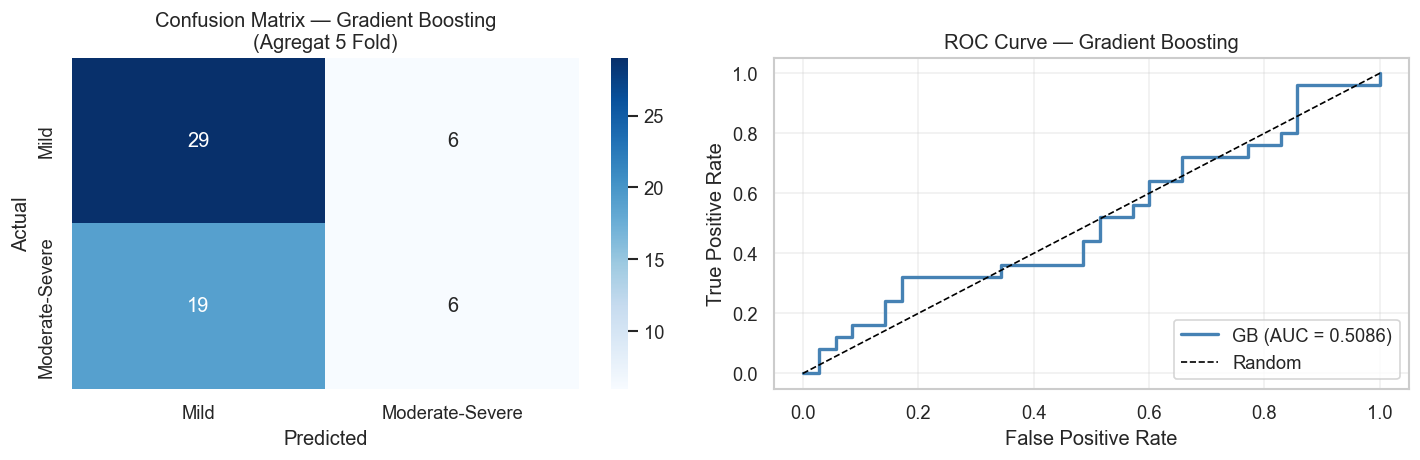


  Section 5 — Ringkasan Gradient Boosting
  Accuracy  : 0.5833 ± 0.1559
  F1-Score  : 0.3016 ± 0.2744
  AUC-ROC   : 0.5257 ± 0.2046
  FN kritis : 19 kasus MS tidak terdeteksi dari 25 total
  Variabel aktif: results_gb, best_model_gb, cm_gb
  Lanjut ke Cell 8 — XGBoost + K-Fold


In [9]:
# CELL 7 — GRADIENT BOOSTING + STRATIFIED K-FOLD
# Deskripsi: Training dan evaluasi Gradient Boosting
#            menggunakan Stratified K-Fold (k=5).
#            StandardScaler di-fit per fold (anti-leakage).
#            Hasil disimpan ke results_gb untuk Cell 10.
# ============================================================

# ── Konfigurasi model ─────────────────────────────────────────
GB_PARAMS = {
    'n_estimators'  : 100,
    'learning_rate' : 0.1,
    'max_depth'     : 3,
    'subsample'     : 0.8,
    'random_state'  : 42
}

# ── Section 1: Inisialisasi ───────────────────────────────────
print("=" * 60)
print("Section 1: Gradient Boosting — Konfigurasi Model")
print("=" * 60)
print("  Algoritma     : Gradient Boosting Classifier")
for k, v in GB_PARAMS.items():
    print(f"  {k:<17}: {v}")

# ── Section 2: Training K-Fold ────────────────────────────────
print("\nSection 2: Training Stratified K-Fold")
print("-" * 60)
print(f"  {'Fold':<6} {'Acc':>6} {'Prec':>6} {'Rec':>6} {'F1':>6} {'AUC':>6}")
print(f"  {'-'*38}")

# Container hasil per fold
fold_metrics_gb = []
all_y_true_gb   = []
all_y_pred_gb   = []
all_y_prob_gb   = []
best_model_gb   = None
best_f1_gb      = -1

for fold, (train_idx, val_idx) in enumerate(
        kfold.split(X_final, y_final), 1):

    # Split data fold
    X_tr, X_vl = X_final[train_idx], X_final[val_idx]
    y_tr, y_vl = y_final[train_idx], y_final[val_idx]

    # StandardScaler fit HANYA pada train fold
    scaler    = StandardScaler()
    X_tr_sc   = scaler.fit_transform(X_tr)
    X_vl_sc   = scaler.transform(X_vl)

    # Training
    model = GradientBoostingClassifier(**GB_PARAMS)
    model.fit(X_tr_sc, y_tr)

    # Prediksi
    y_pred = model.predict(X_vl_sc)
    y_prob = model.predict_proba(X_vl_sc)[:, 1]

    # Hitung metrik
    acc  = accuracy_score(y_vl, y_pred)
    prec = precision_score(y_vl, y_pred, zero_division=0)
    rec  = recall_score(y_vl, y_pred, zero_division=0)
    f1   = f1_score(y_vl, y_pred, zero_division=0)
    auc_score  = roc_auc_score(y_vl, y_prob)

    fold_metrics_gb.append({
        'fold': fold, 'acc': acc, 'prec': prec,
        'rec': rec,   'f1': f1,   'auc': auc_score
    })

    # Simpan prediksi untuk confusion matrix agregat
    all_y_true_gb.extend(y_vl)
    all_y_pred_gb.extend(y_pred)
    all_y_prob_gb.extend(y_prob)

    # Simpan model terbaik berdasarkan F1
    if f1 > best_f1_gb:
        best_f1_gb    = f1
        best_model_gb = model

    print(f"  Fold {fold}  {acc:.4f} {prec:.4f} {rec:.4f} {f1:.4f} {auc_score:.4f}")

# ── Section 3: Rata-rata Metrik ───────────────────────────────
print(f"\nSection 3: Rata-rata Metrik (Mean ± Std)")
print("-" * 60)

df_fold_gb = pd.DataFrame(fold_metrics_gb)
metrics_list = ['acc', 'prec', 'rec', 'f1', 'auc']
label_map    = {
    'acc' : 'Accuracy', 'prec': 'Precision',
    'rec' : 'Recall',   'f1'  : 'F1-Score',
    'auc' : 'AUC-ROC'
}

results_gb = {}   # disimpan untuk Cell 10 (evaluasi komparatif)
for m in metrics_list:
    mean = df_fold_gb[m].mean()
    std  = df_fold_gb[m].std()
    results_gb[m] = {'mean': mean, 'std': std}
    print(f"  {label_map[m]:<11}: {mean:.4f} ± {std:.4f}")

# ── Section 4: Confusion Matrix Agregat ──────────────────────
print(f"\nSection 4: Confusion Matrix Agregat (semua fold)")
print("-" * 60)

cm_gb = confusion_matrix(all_y_true_gb, all_y_pred_gb)
print(f"  TN={cm_gb[0,0]}  FP={cm_gb[0,1]}")
print(f"  FN={cm_gb[1,0]}  TP={cm_gb[1,1]}")
print(f"\n  Interpretasi:")
print(f"  TP (Moderate-Severe terdeteksi benar) : {cm_gb[1,1]}")
print(f"  TN (Mild terdeteksi benar)            : {cm_gb[0,0]}")
print(f"  FP (Mild salah diklasifikasi sebagai MS): {cm_gb[0,1]}")
print(f"  FN (MS terlewat — paling kritis)       : {cm_gb[1,0]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

print(f"\n  Classification Report (Agregat 5 Fold):")
print(classification_report(
    all_y_true_gb, all_y_pred_gb,
    target_names=['Mild (0)', 'Moderate-Severe (1)'],
    zero_division=0
))

# Plot confusion matrix
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Mild', 'Moderate-Severe'],
            yticklabels=['Mild', 'Moderate-Severe'],
            ax=axes[0])
axes[0].set_title('Confusion Matrix — Gradient Boosting\n(Agregat 5 Fold)')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# Plot ROC Curve
fpr, tpr, _ = roc_curve(all_y_true_gb, all_y_prob_gb)
roc_auc_val = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='steelblue', lw=2,
             label=f'GB (AUC = {roc_auc_val:.4f})')
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — Gradient Boosting')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNN/gb_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Section 5: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 5 — Ringkasan Gradient Boosting")
print("=" * 60)
print(f"  Accuracy  : {results_gb['acc']['mean']:.4f} ± {results_gb['acc']['std']:.4f}")
print(f"  F1-Score  : {results_gb['f1']['mean']:.4f} ± {results_gb['f1']['std']:.4f}")
print(f"  AUC-ROC   : {results_gb['auc']['mean']:.4f} ± {results_gb['auc']['std']:.4f}")
print(f"  FN kritis : {cm_gb[1,0]} kasus MS tidak terdeteksi dari {sum(all_y_true_gb)} total")
print("=" * 60)
print("  Variabel aktif: results_gb, best_model_gb, cm_gb")
print("  Lanjut ke Cell 8 — XGBoost + K-Fold")

Section 1: XGBoost — Konfigurasi Model
  Algoritma     : XGBoost Classifier
  n_estimators          : 100
  learning_rate         : 0.1
  max_depth             : 3
  subsample             : 0.8
  colsample_bytree      : 0.8
  use_label_encoder     : False
  eval_metric           : logloss
  random_state          : 42
  verbosity             : 0

Section 2: Training Stratified K-Fold
------------------------------------------------------------
  Fold      Acc   Prec    Rec     F1    AUC
  --------------------------------------
  Fold 1  0.5833 0.5000 0.4000 0.4444 0.6000
  Fold 2  0.5000 0.3333 0.2000 0.2500 0.2000
  Fold 3  0.7500 0.7500 0.6000 0.6667 0.6857
  Fold 4  0.4167 0.3333 0.4000 0.3636 0.3714
  Fold 5  0.5833 0.5000 0.2000 0.2857 0.5714

Section 3: Rata-rata Metrik (Mean ± Std)
------------------------------------------------------------
  Accuracy   : 0.5667 ± 0.1236
  Precision  : 0.4833 ± 0.1708
  Recall     : 0.3600 ± 0.1673
  F1-Score   : 0.4021 ± 0.1658
  AUC-ROC    : 0

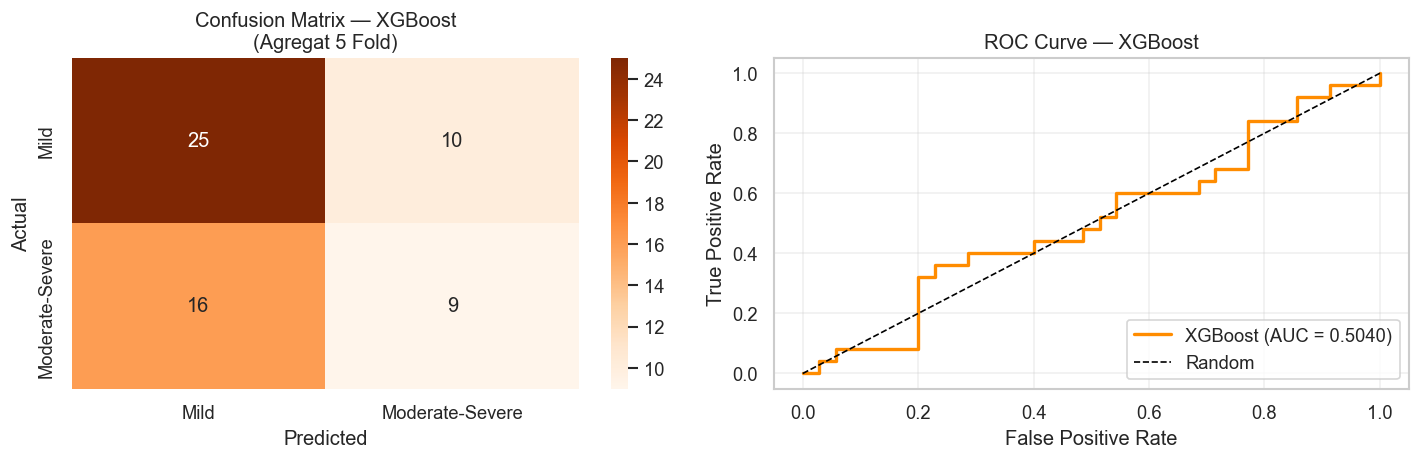


  Section 5 — Ringkasan XGBoost
  Accuracy  : 0.5667 ± 0.1236
  F1-Score  : 0.4021 ± 0.1658
  AUC-ROC   : 0.4857 ± 0.1969
  FN kritis : 16 kasus MS tidak terdeteksi dari 25 total
  Variabel aktif: results_xgb, best_model_xgb, cm_xgb
  Lanjut ke Cell 9 — MLP + K-Fold


In [10]:
# CELL 8 — XGBOOST + STRATIFIED K-FOLD
# Deskripsi: Training dan evaluasi XGBoost menggunakan
#            Stratified K-Fold (k=5) yang sama dengan Cell 7.
#            Variabel auc_score digunakan di dalam loop
#            untuk menghindari konflik nama dengan fungsi auc().
# ============================================================

# ── Konfigurasi model ─────────────────────────────────────────
XGB_PARAMS = {
    'n_estimators'   : 100,
    'learning_rate'  : 0.1,
    'max_depth'      : 3,
    'subsample'      : 0.8,
    'colsample_bytree': 0.8,
    'use_label_encoder': False,
    'eval_metric'    : 'logloss',
    'random_state'   : 42,
    'verbosity'      : 0
}

# ── Section 1: Inisialisasi ───────────────────────────────────
print("=" * 60)
print("Section 1: XGBoost — Konfigurasi Model")
print("=" * 60)
print("  Algoritma     : XGBoost Classifier")
for k, v in XGB_PARAMS.items():
    print(f"  {k:<22}: {v}")

# ── Section 2: Training K-Fold ────────────────────────────────
print("\nSection 2: Training Stratified K-Fold")
print("-" * 60)
print(f"  {'Fold':<6} {'Acc':>6} {'Prec':>6} {'Rec':>6} {'F1':>6} {'AUC':>6}")
print(f"  {'-'*38}")

fold_metrics_xgb = []
all_y_true_xgb   = []
all_y_pred_xgb   = []
all_y_prob_xgb   = []
best_model_xgb   = None
best_f1_xgb      = -1

for fold, (train_idx, val_idx) in enumerate(
        kfold.split(X_final, y_final), 1):

    # Split data fold
    X_tr, X_vl = X_final[train_idx], X_final[val_idx]
    y_tr, y_vl = y_final[train_idx], y_final[val_idx]

    # StandardScaler fit HANYA pada train fold
    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_vl_sc = scaler.transform(X_vl)

    # Training
    model = XGBClassifier(**XGB_PARAMS)
    model.fit(X_tr_sc, y_tr)

    # Prediksi
    y_pred = model.predict(X_vl_sc)
    y_prob = model.predict_proba(X_vl_sc)[:, 1]

    # Hitung metrik — auc_score untuk hindari konflik nama fungsi auc()
    acc       = accuracy_score(y_vl, y_pred)
    prec      = precision_score(y_vl, y_pred, zero_division=0)
    rec       = recall_score(y_vl, y_pred, zero_division=0)
    f1        = f1_score(y_vl, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_vl, y_prob)

    fold_metrics_xgb.append({
        'fold': fold, 'acc': acc,       'prec': prec,
        'rec' : rec,  'f1' : f1,        'auc' : auc_score
    })

    all_y_true_xgb.extend(y_vl)
    all_y_pred_xgb.extend(y_pred)
    all_y_prob_xgb.extend(y_prob)

    if f1 > best_f1_xgb:
        best_f1_xgb    = f1
        best_model_xgb = model

    print(f"  Fold {fold}  {acc:.4f} {prec:.4f} {rec:.4f} {f1:.4f} {auc_score:.4f}")

# ── Section 3: Rata-rata Metrik ───────────────────────────────
print(f"\nSection 3: Rata-rata Metrik (Mean ± Std)")
print("-" * 60)

df_fold_xgb = pd.DataFrame(fold_metrics_xgb)
metrics_list = ['acc', 'prec', 'rec', 'f1', 'auc']
label_map    = {
    'acc' : 'Accuracy', 'prec': 'Precision',
    'rec' : 'Recall',   'f1'  : 'F1-Score',
    'auc' : 'AUC-ROC'
}

results_xgb = {}
for m in metrics_list:
    mean = df_fold_xgb[m].mean()
    std  = df_fold_xgb[m].std()
    results_xgb[m] = {'mean': mean, 'std': std}
    print(f"  {label_map[m]:<11}: {mean:.4f} ± {std:.4f}")

# ── Section 4: Confusion Matrix Agregat ──────────────────────
print(f"\nSection 4: Confusion Matrix Agregat (semua fold)")
print("-" * 60)

cm_xgb = confusion_matrix(all_y_true_xgb, all_y_pred_xgb)
print(f"  TN={cm_xgb[0,0]}  FP={cm_xgb[0,1]}")
print(f"  FN={cm_xgb[1,0]}  TP={cm_xgb[1,1]}")
print(f"\n  Interpretasi:")
print(f"  TP (Moderate-Severe terdeteksi benar) : {cm_xgb[1,1]}")
print(f"  TN (Mild terdeteksi benar)            : {cm_xgb[0,0]}")
print(f"  FP (Mild salah diklasifikasi sbg MS)  : {cm_xgb[0,1]}")
print(f"  FN (MS terlewat — paling kritis)      : {cm_xgb[1,0]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

print(f"\n  Classification Report (Agregat 5 Fold):")
print(classification_report(
    all_y_true_xgb, all_y_pred_xgb,
    target_names=['Mild (0)', 'Moderate-Severe (1)'],
    zero_division=0
))

sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Mild', 'Moderate-Severe'],
            yticklabels=['Mild', 'Moderate-Severe'],
            ax=axes[0])
axes[0].set_title('Confusion Matrix — XGBoost\n(Agregat 5 Fold)')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

fpr_xgb, tpr_xgb, _ = roc_curve(all_y_true_xgb, all_y_prob_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)
axes[1].plot(fpr_xgb, tpr_xgb, color='darkorange', lw=2,
             label=f'XGBoost (AUC = {roc_auc_xgb:.4f})')
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — XGBoost')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNN/xgb_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Section 5: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 5 — Ringkasan XGBoost")
print("=" * 60)
print(f"  Accuracy  : {results_xgb['acc']['mean']:.4f} ± {results_xgb['acc']['std']:.4f}")
print(f"  F1-Score  : {results_xgb['f1']['mean']:.4f} ± {results_xgb['f1']['std']:.4f}")
print(f"  AUC-ROC   : {results_xgb['auc']['mean']:.4f} ± {results_xgb['auc']['std']:.4f}")
print(f"  FN kritis : {cm_xgb[1,0]} kasus MS tidak terdeteksi dari {sum(all_y_true_xgb)} total")
print("=" * 60)
print("  Variabel aktif: results_xgb, best_model_xgb, cm_xgb")
print("  Lanjut ke Cell 9 — MLP + K-Fold")

Section 1: MLP — Konfigurasi Model
  Algoritma     : Multi-Layer Perceptron (sklearn)
  Arsitektur     : Input(47) → Dense(64) → Dense(32) → Output(1)
  hidden_layer_sizes    : (64, 32)
  activation            : relu
  solver                : adam
  alpha                 : 0.01
  learning_rate         : adaptive
  learning_rate_init    : 0.001
  max_iter              : 500
  early_stopping        : True
  validation_fraction   : 0.1
  n_iter_no_change      : 20
  random_state          : 42

Section 2: Training Stratified K-Fold
------------------------------------------------------------
  Fold      Acc   Prec    Rec     F1    AUC   Iter
  ---------------------------------------------
  Fold 1  0.6667 0.6000 0.6000 0.6000 0.7429    22
  Fold 2  0.5000 0.3333 0.2000 0.2500 0.5143    22
  Fold 3  0.6667 1.0000 0.2000 0.3333 0.7429    22
  Fold 4  0.7500 1.0000 0.4000 0.5714 0.8857    22
  Fold 5  0.5833 0.5000 0.6000 0.5455 0.5714    22

Section 3: Rata-rata Metrik (Mean ± Std)
---------

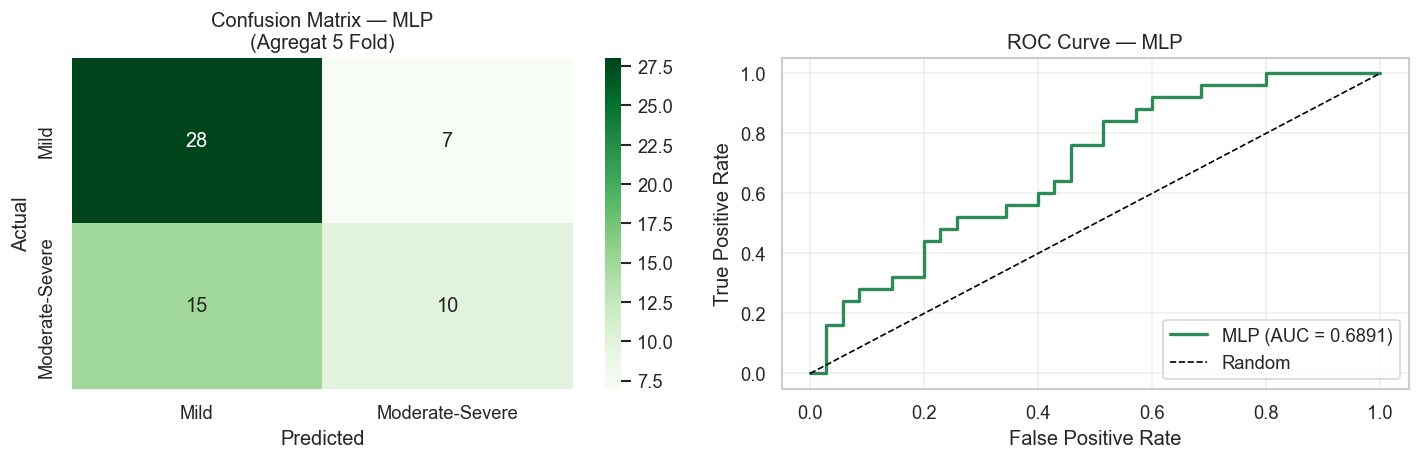


  Section 5 — Ringkasan MLP
  Accuracy  : 0.6333 ± 0.0950
  F1-Score  : 0.4600 ± 0.1577
  AUC-ROC   : 0.6914 ± 0.1490
  FN kritis : 15 kasus MS tidak terdeteksi dari 25 total
  Arsitektur: Input(47) → Dense(64) → Dense(32) → Output(1)
  Early stop: iterasi aktual per fold tercatat di Section 2
  Variabel aktif: results_mlp, best_model_mlp, cm_mlp
  Lanjut ke Cell 10 — Evaluasi Komparatif


In [11]:
# ============================================================
# CELL 9 — MLP + STRATIFIED K-FOLD
# Deskripsi: Training dan evaluasi Multi-Layer Perceptron
#            menggunakan Stratified K-Fold (k=5) identik
#            dengan Cell 7 dan 8. Arsitektur MLP dirancang
#            proporsional terhadap jumlah fitur PCA (47)
#            dan ukuran dataset (60 sampel).
# ============================================================

# ── Konfigurasi model ─────────────────────────────────────────
# Arsitektur (64, 32): layer pertama 64 neuron, layer kedua 32
# Dipilih proporsional — hindari overfitting pada n=60
# alpha=0.01: L2 regularization untuk dataset kecil
# early_stopping=True: hentikan training jika val_loss tidak membaik
MLP_PARAMS = {
    'hidden_layer_sizes' : (64, 32),
    'activation'         : 'relu',
    'solver'             : 'adam',
    'alpha'              : 0.01,
    'learning_rate'      : 'adaptive',
    'learning_rate_init' : 0.001,
    'max_iter'           : 500,
    'early_stopping'     : True,
    'validation_fraction': 0.1,
    'n_iter_no_change'   : 20,
    'random_state'       : 42
}

# ── Section 1: Inisialisasi ───────────────────────────────────
print("=" * 60)
print("Section 1: MLP — Konfigurasi Model")
print("=" * 60)
print("  Algoritma     : Multi-Layer Perceptron (sklearn)")
print(f"  Arsitektur     : Input(47) → Dense(64) → Dense(32) → Output(1)")
for k, v in MLP_PARAMS.items():
    print(f"  {k:<22}: {v}")

# ── Section 2: Training K-Fold ────────────────────────────────
print("\nSection 2: Training Stratified K-Fold")
print("-" * 60)
print(f"  {'Fold':<6} {'Acc':>6} {'Prec':>6} {'Rec':>6} {'F1':>6} {'AUC':>6} {'Iter':>6}")
print(f"  {'-'*45}")

fold_metrics_mlp = []
all_y_true_mlp   = []
all_y_pred_mlp   = []
all_y_prob_mlp   = []
best_model_mlp   = None
best_f1_mlp      = -1

for fold, (train_idx, val_idx) in enumerate(
        kfold.split(X_final, y_final), 1):

    # Split data fold
    X_tr, X_vl = X_final[train_idx], X_final[val_idx]
    y_tr, y_vl = y_final[train_idx], y_final[val_idx]

    # StandardScaler fit HANYA pada train fold
    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_vl_sc = scaler.transform(X_vl)

    # Training
    model = MLPClassifier(**MLP_PARAMS)
    model.fit(X_tr_sc, y_tr)

    # Prediksi
    y_pred = model.predict(X_vl_sc)
    y_prob = model.predict_proba(X_vl_sc)[:, 1]

    # Hitung metrik — auc_score untuk hindari konflik nama fungsi auc()
    acc       = accuracy_score(y_vl, y_pred)
    prec      = precision_score(y_vl, y_pred, zero_division=0)
    rec       = recall_score(y_vl, y_pred, zero_division=0)
    f1        = f1_score(y_vl, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_vl, y_prob)
    n_iter    = model.n_iter_   # iterasi aktual (early stopping)

    fold_metrics_mlp.append({
        'fold': fold, 'acc': acc,       'prec': prec,
        'rec' : rec,  'f1' : f1,        'auc' : auc_score
    })

    all_y_true_mlp.extend(y_vl)
    all_y_pred_mlp.extend(y_pred)
    all_y_prob_mlp.extend(y_prob)

    if f1 > best_f1_mlp:
        best_f1_mlp    = f1
        best_model_mlp = model

    print(f"  Fold {fold}  {acc:.4f} {prec:.4f} {rec:.4f} "
          f"{f1:.4f} {auc_score:.4f} {n_iter:>5}")

# ── Section 3: Rata-rata Metrik ───────────────────────────────
print(f"\nSection 3: Rata-rata Metrik (Mean ± Std)")
print("-" * 60)

df_fold_mlp  = pd.DataFrame(fold_metrics_mlp)
metrics_list = ['acc', 'prec', 'rec', 'f1', 'auc']
label_map    = {
    'acc' : 'Accuracy', 'prec': 'Precision',
    'rec' : 'Recall',   'f1'  : 'F1-Score',
    'auc' : 'AUC-ROC'
}

results_mlp = {}
for m in metrics_list:
    mean = df_fold_mlp[m].mean()
    std  = df_fold_mlp[m].std()
    results_mlp[m] = {'mean': mean, 'std': std}
    print(f"  {label_map[m]:<11}: {mean:.4f} ± {std:.4f}")

# ── Section 4: Confusion Matrix Agregat ──────────────────────
print(f"\nSection 4: Confusion Matrix Agregat (semua fold)")
print("-" * 60)

cm_mlp = confusion_matrix(all_y_true_mlp, all_y_pred_mlp)
print(f"  TN={cm_mlp[0,0]}  FP={cm_mlp[0,1]}")
print(f"  FN={cm_mlp[1,0]}  TP={cm_mlp[1,1]}")
print(f"\n  Interpretasi:")
print(f"  TP (Moderate-Severe terdeteksi benar) : {cm_mlp[1,1]}")
print(f"  TN (Mild terdeteksi benar)            : {cm_mlp[0,0]}")
print(f"  FP (Mild salah diklasifikasi sbg MS)  : {cm_mlp[0,1]}")
print(f"  FN (MS terlewat — paling kritis)      : {cm_mlp[1,0]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

print(f"\n  Classification Report (Agregat 5 Fold):")
print(classification_report(
    all_y_true_mlp, all_y_pred_mlp,
    target_names=['Mild (0)', 'Moderate-Severe (1)'],
    zero_division=0
))

sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Mild', 'Moderate-Severe'],
            yticklabels=['Mild', 'Moderate-Severe'],
            ax=axes[0])
axes[0].set_title('Confusion Matrix — MLP\n(Agregat 5 Fold)')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

fpr_mlp, tpr_mlp, _ = roc_curve(all_y_true_mlp, all_y_prob_mlp)
roc_auc_mlp = auc(fpr_mlp, tpr_mlp)
axes[1].plot(fpr_mlp, tpr_mlp, color='seagreen', lw=2,
             label=f'MLP (AUC = {roc_auc_mlp:.4f})')
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — MLP')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNN/mlp_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Section 5: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 5 — Ringkasan MLP")
print("=" * 60)
print(f"  Accuracy  : {results_mlp['acc']['mean']:.4f} ± {results_mlp['acc']['std']:.4f}")
print(f"  F1-Score  : {results_mlp['f1']['mean']:.4f} ± {results_mlp['f1']['std']:.4f}")
print(f"  AUC-ROC   : {results_mlp['auc']['mean']:.4f} ± {results_mlp['auc']['std']:.4f}")
print(f"  FN kritis : {cm_mlp[1,0]} kasus MS tidak terdeteksi dari {sum(all_y_true_mlp)} total")
print(f"  Arsitektur: Input(47) → Dense(64) → Dense(32) → Output(1)")
print(f"  Early stop: iterasi aktual per fold tercatat di Section 2")
print("=" * 60)
print("  Variabel aktif: results_mlp, best_model_mlp, cm_mlp")
print("  Lanjut ke Cell 10 — Evaluasi Komparatif")

Section 1: Tabel Komparatif Metrik (Mean ± Std)


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Gradient Boosting,0.5833 ± 0.1559,0.4167 ± 0.3727,0.2400 ± 0.2191,0.3016 ± 0.2744,0.5257 ± 0.2046
XGBoost,0.5667 ± 0.1236,0.4833 ± 0.1708,0.3600 ± 0.1673,0.4021 ± 0.1658,0.4857 ± 0.1969
MLP,0.6333 ± 0.0950,0.6867 ± 0.3015,0.4000 ± 0.2000,0.4600 ± 0.1577,0.6914 ± 0.1490



Section 2: Ranking Berdasarkan F1-Score
------------------------------------------------------------
  Rank  Model                 F1-Score   AUC-ROC  Accuracy
  -------------------------------------------------------
  #1    MLP                     0.4600    0.6914    0.6333
  #2    XGBoost                 0.4021    0.4857    0.5667
  #3    Gradient Boosting       0.3016    0.5257    0.5833

  → Model terbaik (F1): MLP

Section 3: Visualisasi Bar Chart Komparatif
------------------------------------------------------------


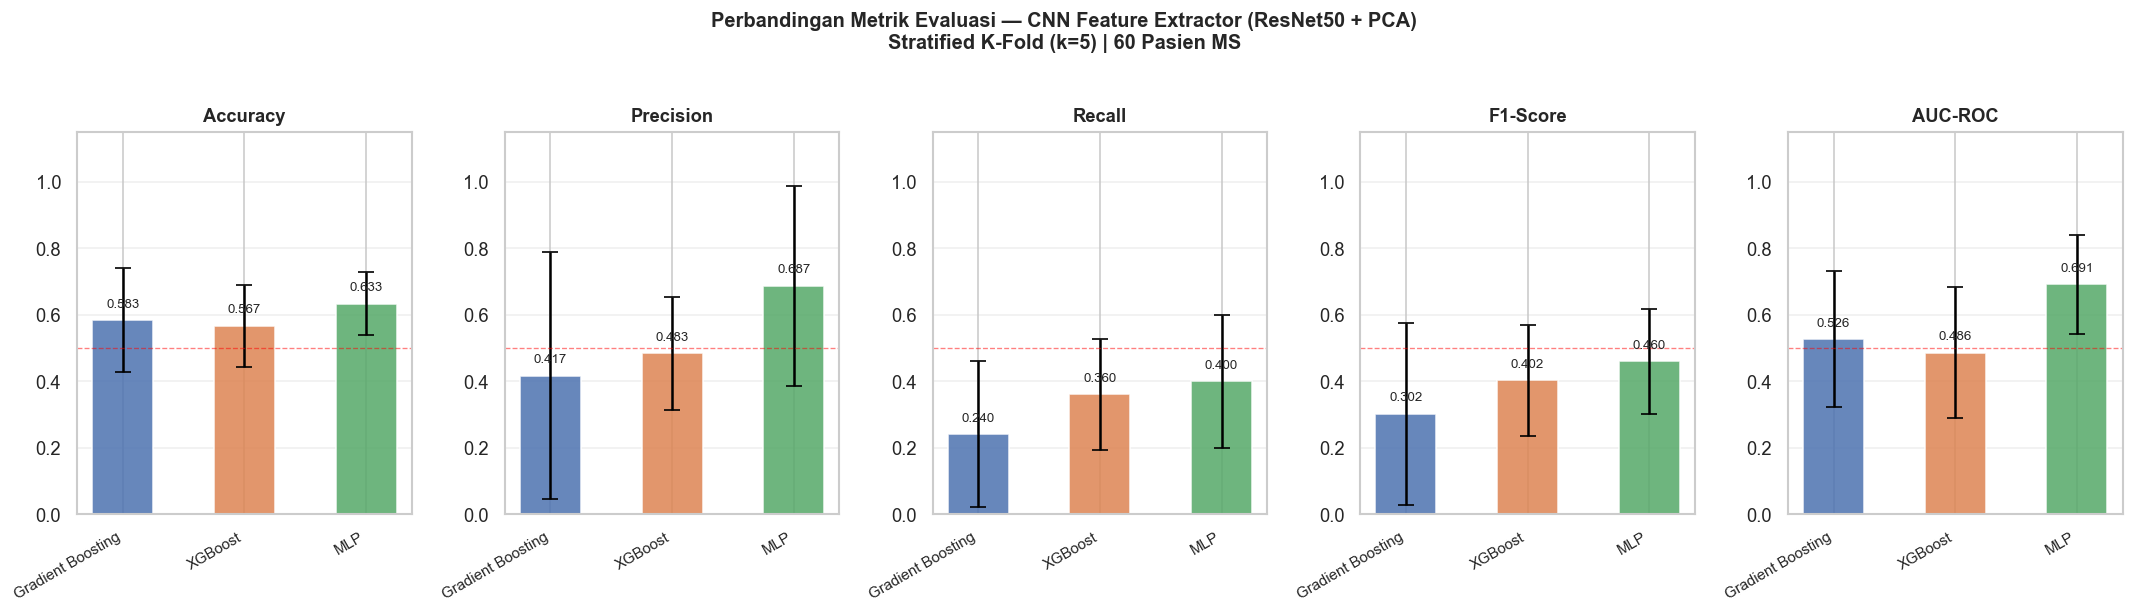

  Plot disimpan: 'ConfigdanOutputCNN/komparatif_bar_chart.png'

Section 4: ROC Curve Gabungan
------------------------------------------------------------


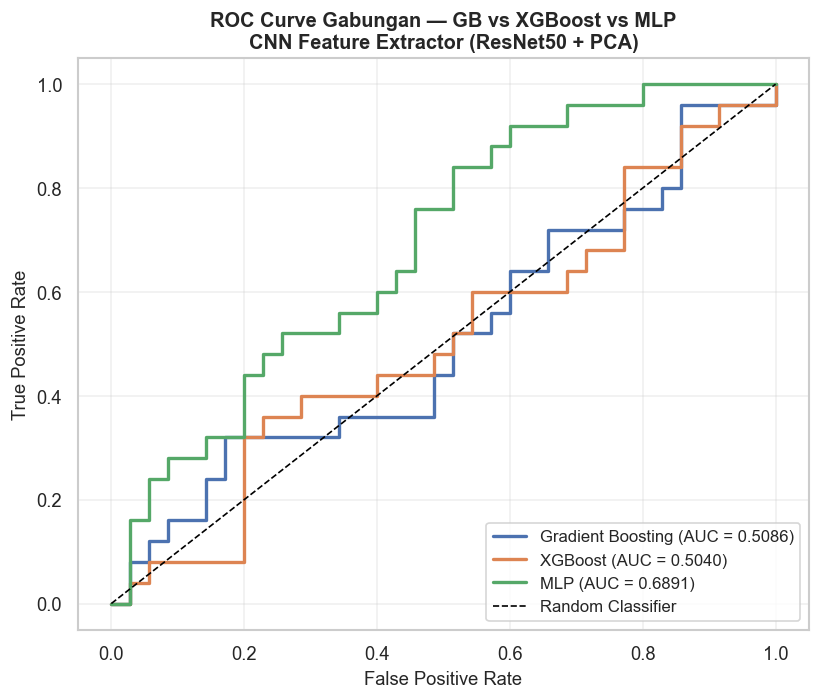

  Plot disimpan: 'ConfigdanOutputCNN/roc_curve_gabungan.png'

  Section 5 — Kesimpulan Eksperimen 1
  Pendekatan : CNN Feature Extractor (ResNet50 + PCA)
  Fitur      : 6144 → PCA → 47 komponen (95.48% variance)
  Dataset    : 60 pasien MS | 35 Mild | 25 Moderate-Severe
  Validasi   : Stratified K-Fold (k=5)

  Model                 F1-Score   AUC-ROC  Accuracy
  --------------------------------------------------
  MLP                     0.4600    0.6914    0.6333 ← TERBAIK
  XGBoost                 0.4021    0.4857    0.5667
  Gradient Boosting       0.3016    0.5257    0.5833

  Catatan:
  Performa ketiga model masih terbatas — konsisten dengan
  keterbatasan dataset (n=60, rasio sampel:fitur rendah).
  Hasil ini menjadi baseline untuk tahap berikutnya:
  augmentasi data menggunakan cGAN.
  [SPACE UNTUK cGAN — Cell 11 dst]


In [12]:
# CELL 10 — EVALUASI KOMPARATIF
# Deskripsi: Membandingkan performa GB, XGBoost, dan MLP
#            dalam satu tabel dan visualisasi terpadu.
#            Output cell ini langsung masuk bab hasil skripsi.
# ============================================================

# ── Section 1: Tabel Komparatif Metrik ───────────────────────
print("=" * 60)
print("Section 1: Tabel Komparatif Metrik (Mean ± Std)")
print("=" * 60)

metrics_list = ['acc', 'prec', 'rec', 'f1', 'auc']
label_map    = {
    'acc' : 'Accuracy', 'prec': 'Precision',
    'rec' : 'Recall',   'f1'  : 'F1-Score',
    'auc' : 'AUC-ROC'
}
model_results = {
    'Gradient Boosting': results_gb,
    'XGBoost'          : results_xgb,
    'MLP'              : results_mlp,
}

# Bangun DataFrame komparatif
rows = []
for model_name, res in model_results.items():
    row = {'Model': model_name}
    for m in metrics_list:
        row[label_map[m]] = f"{res[m]['mean']:.4f} ± {res[m]['std']:.4f}"
    rows.append(row)

df_comparison = pd.DataFrame(rows).set_index('Model')
display(df_comparison)

# ── Section 2: Tabel Nilai Mean Saja (untuk ranking) ─────────
print("\nSection 2: Ranking Berdasarkan F1-Score")
print("-" * 60)

rows_mean = []
for model_name, res in model_results.items():
    row = {'Model': model_name}
    for m in metrics_list:
        row[label_map[m]] = res[m]['mean']
    rows_mean.append(row)

df_mean = pd.DataFrame(rows_mean).set_index('Model')

# Ranking berdasarkan F1 → AUC sebagai tiebreaker
df_ranked = df_mean.sort_values(
    by=['F1-Score', 'AUC-ROC'], ascending=False)
df_ranked['Rank'] = range(1, len(df_ranked) + 1)

print(f"  {'Rank':<5} {'Model':<20} {'F1-Score':>9} {'AUC-ROC':>9} {'Accuracy':>9}")
print(f"  {'-'*55}")
for model_name, row in df_ranked.iterrows():
    print(f"  #{int(row['Rank']):<4} {model_name:<20} "
          f"{row['F1-Score']:>9.4f} {row['AUC-ROC']:>9.4f} "
          f"{row['Accuracy']:>9.4f}")

best_model_name = df_ranked.index[0]
print(f"\n  → Model terbaik (F1): {best_model_name}")

# ── Section 3: Bar Chart Komparatif per Metrik ───────────────
print("\nSection 3: Visualisasi Bar Chart Komparatif")
print("-" * 60)

fig, axes = plt.subplots(1, 5, figsize=(18, 5))
colors     = ['#4C72B0', '#DD8452', '#55A868']
model_names = list(model_results.keys())

for idx, m in enumerate(metrics_list):
    means = [model_results[mn][m]['mean'] for mn in model_names]
    stds  = [model_results[mn][m]['std']  for mn in model_names]
    bars  = axes[idx].bar(
        model_names, means, yerr=stds,
        color=colors, edgecolor='white',
        capsize=5, width=0.5, alpha=0.85
    )
    axes[idx].set_title(label_map[m], fontsize=11, fontweight='bold')
    axes[idx].set_ylim([0, 1.15])
    axes[idx].set_xticklabels(model_names, rotation=30, ha='right', fontsize=9)
    axes[idx].axhline(y=0.5, color='red', linestyle='--',
                       linewidth=0.8, alpha=0.5, label='baseline 0.5')
    axes[idx].grid(True, axis='y', alpha=0.3)
    for bar, mean in zip(bars, means):
        axes[idx].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.03,
            f'{mean:.3f}', ha='center', va='bottom', fontsize=8
        )

plt.suptitle(
    'Perbandingan Metrik Evaluasi — CNN Feature Extractor (ResNet50 + PCA)\n'
    'Stratified K-Fold (k=5) | 60 Pasien MS',
    fontsize=12, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig('ConfigdanOutputCNN/komparatif_bar_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Plot disimpan: 'ConfigdanOutputCNN/komparatif_bar_chart.png'")

# ── Section 4: ROC Curve Gabungan ─────────────────────────────
print("\nSection 4: ROC Curve Gabungan")
print("-" * 60)

fig, ax = plt.subplots(figsize=(7, 6))

roc_data = [
    (all_y_true_gb,  all_y_prob_gb,  'Gradient Boosting', '#4C72B0'),
    (all_y_true_xgb, all_y_prob_xgb, 'XGBoost',           '#DD8452'),
    (all_y_true_mlp, all_y_prob_mlp, 'MLP',               '#55A868'),
]

for y_true, y_prob, name, color in roc_data:
    fpr_r, tpr_r, _ = roc_curve(y_true, y_prob)
    roc_val          = auc(fpr_r, tpr_r)
    ax.plot(fpr_r, tpr_r, color=color, lw=2,
            label=f'{name} (AUC = {roc_val:.4f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.set_title(
    'ROC Curve Gabungan — GB vs XGBoost vs MLP\n'
    'CNN Feature Extractor (ResNet50 + PCA)',
    fontsize=12, fontweight='bold'
)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('ConfigdanOutputCNN/roc_curve_gabungan.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Plot disimpan: 'ConfigdanOutputCNN/roc_curve_gabungan.png'")

# ── Section 5: Ringkasan Akhir & Kesimpulan Eksperimen 1 ─────
print("\n" + "=" * 60)
print("  Section 5 — Kesimpulan Eksperimen 1")
print("=" * 60)
print("  Pendekatan : CNN Feature Extractor (ResNet50 + PCA)")
print(f"  Fitur      : 6144 → PCA → 47 komponen (95.48% variance)")
print(f"  Dataset    : 60 pasien MS | 35 Mild | 25 Moderate-Severe")
print(f"  Validasi   : Stratified K-Fold (k=5)")
print(f"\n  {'Model':<20} {'F1-Score':>9} {'AUC-ROC':>9} {'Accuracy':>9}")
print(f"  {'-'*50}")
for model_name, row in df_ranked.iterrows():
    marker = " ← TERBAIK" if model_name == best_model_name else ""
    print(f"  {model_name:<20} {row['F1-Score']:>9.4f} "
          f"{row['AUC-ROC']:>9.4f} {row['Accuracy']:>9.4f}{marker}")

print(f"\n  Catatan:")
print(f"  Performa ketiga model masih terbatas — konsisten dengan")
print(f"  keterbatasan dataset (n=60, rasio sampel:fitur rendah).")
print(f"  Hasil ini menjadi baseline untuk tahap berikutnya:")
print(f"  augmentasi data menggunakan cGAN.")
print("=" * 60)
print("  [SPACE UNTUK cGAN — Cell 11 dst]")
print("=" * 60)

Section 1: Figure Dashboard Hasil Eksperimen 1


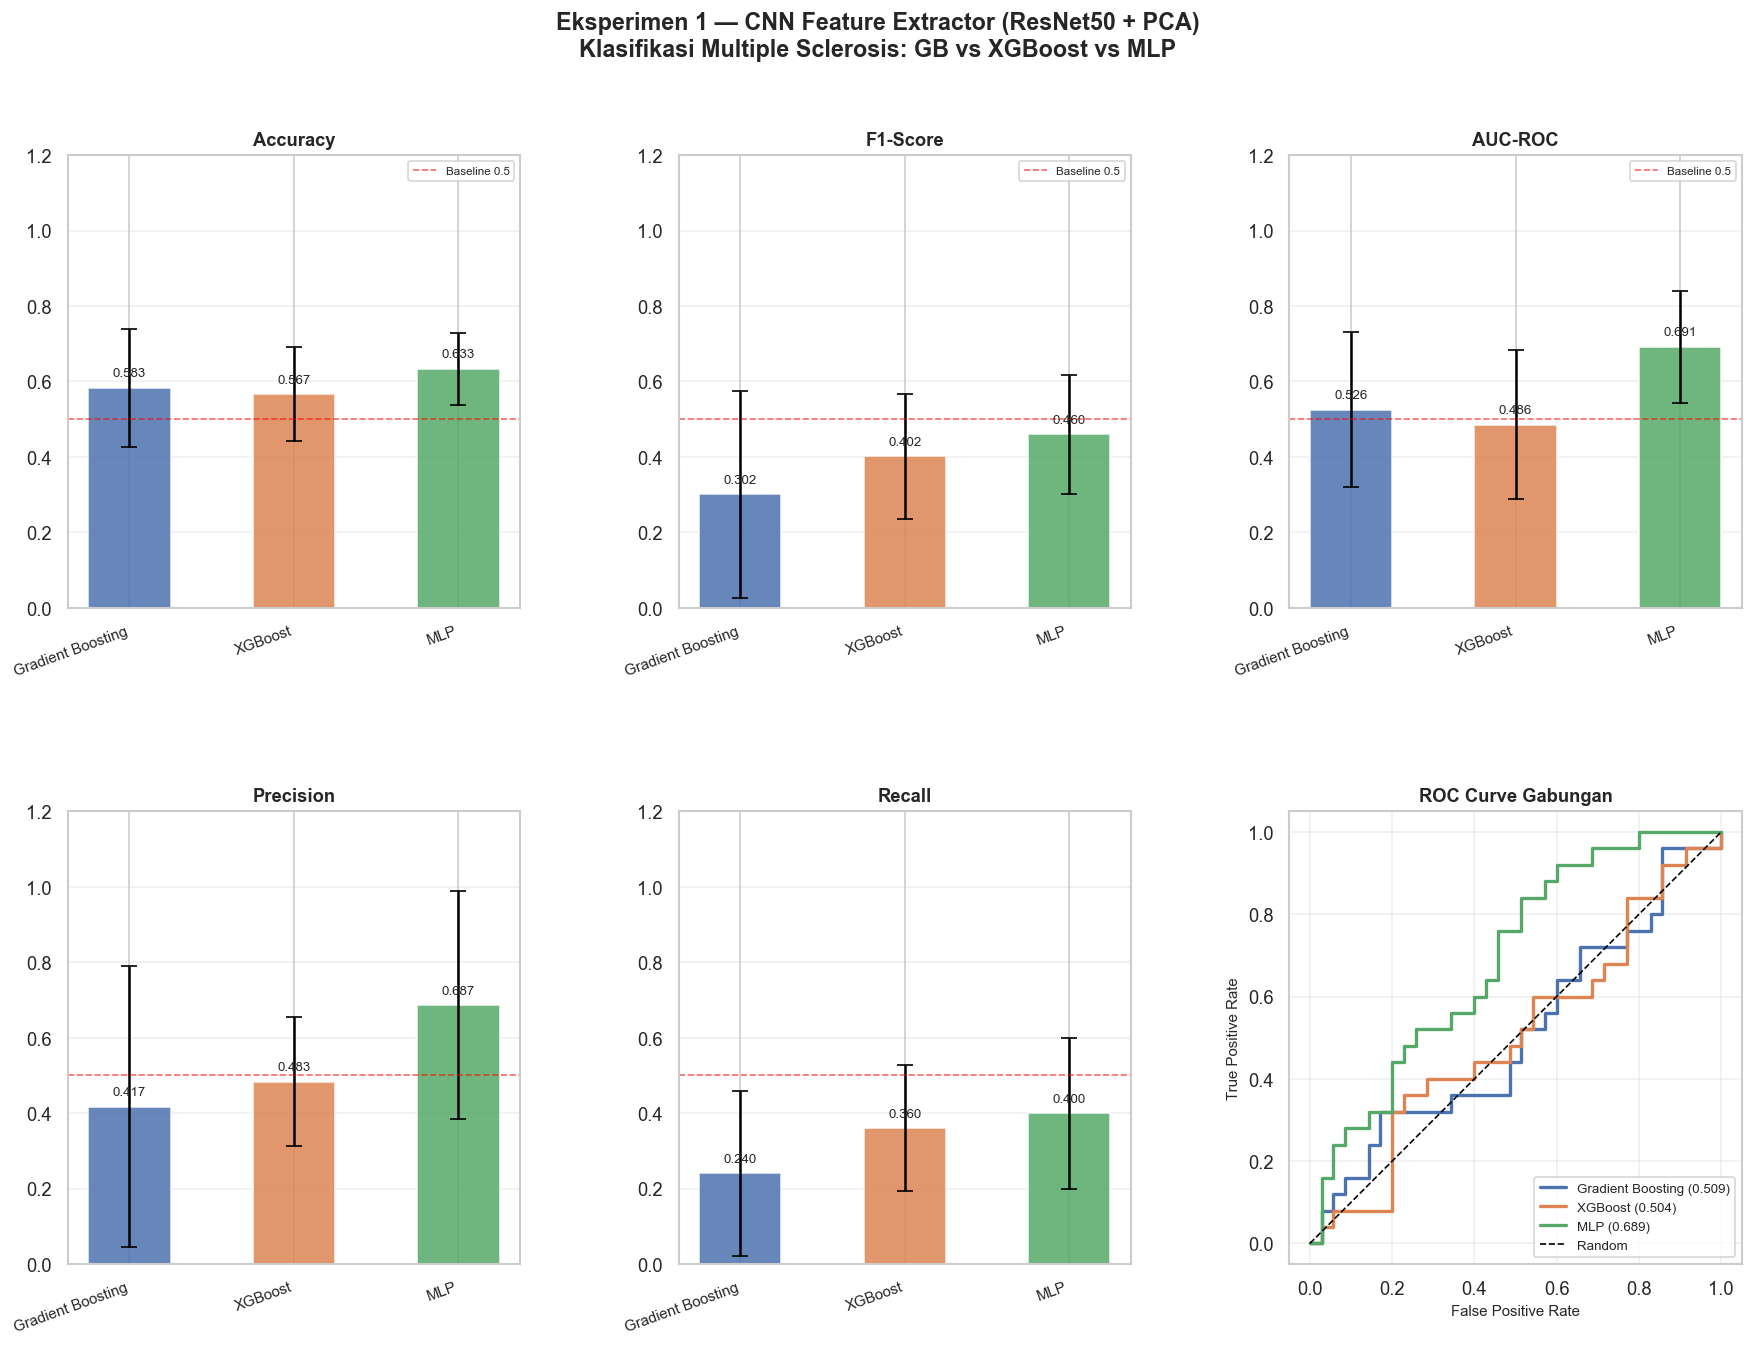

  Figure disimpan: exports_exp1/dashboard_eksperimen1.png

Section 2: Export Artefak Pipeline
------------------------------------------------------------
  ✓ best_model_gb.pkl                      — Model GB terbaik (F1 tertinggi)
  ✓ best_model_xgb.pkl                     — Model XGBoost terbaik
  ✓ best_model_mlp.pkl                     — Model MLP terbaik
  ✓ pca_final.pkl                          — Objek PCA (47 komponen)
  ✓ scaler_pca.pkl                         — StandardScaler untuk PCA
  ✓ df_exp1_features_label.csv             — Fitur CNN + label (input cGAN)
  ✓ tabel_komparatif_exp1.csv              — Tabel hasil komparatif
  ✓ dashboard_eksperimen1.png              — Figure dashboard

Section 3: Ringkasan Naratif Eksperimen 1
------------------------------------------------------------

  [DRAF PARAGRAF — BAB HASIL & PEMBAHASAN]
  ─────────────────────────────────────────
  Eksperimen 1 mengevaluasi pendekatan CNN Feature Extractor
  menggunakan arsitektur ResNet50 pretra

In [13]:
# CELL 11 — VISUALISASI FINAL + EXPORT
# Deskripsi: Figure publikasi-ready, export artefak pipeline,
#            dan ringkasan naratif hasil Eksperimen 1.
#            Space kosong disiapkan untuk Eksperimen 2 (cGAN).
# ============================================================

import os
EXPORT_DIR = "exports_exp1"
os.makedirs(EXPORT_DIR, exist_ok=True)

# ── Section 1: Figure Utama — Dashboard Hasil Eksperimen 1 ───
print("=" * 60)
print("Section 1: Figure Dashboard Hasil Eksperimen 1")
print("=" * 60)

fig = plt.figure(figsize=(18, 12))
fig.suptitle(
    'Eksperimen 1 — CNN Feature Extractor (ResNet50 + PCA)\n'
    'Klasifikasi Multiple Sclerosis: GB vs XGBoost vs MLP',
    fontsize=14, fontweight='bold', y=0.98
)

gs = gridspec.GridSpec(2, 3, figure=fig,
                        hspace=0.45, wspace=0.35)

colors      = ['#4C72B0', '#DD8452', '#55A868']
model_names = ['Gradient Boosting', 'XGBoost', 'MLP']
metrics_plot = [
    ('acc',  'Accuracy'),
    ('f1',   'F1-Score'),
    ('auc',  'AUC-ROC'),
    ('prec', 'Precision'),
    ('rec',  'Recall'),
]

# Baris atas — 3 metrik utama (Accuracy, F1, AUC)
for col, (m_key, m_label) in enumerate(metrics_plot[:3]):
    ax = fig.add_subplot(gs[0, col])
    means = [model_results[mn][m_key]['mean'] for mn in model_names]
    stds  = [model_results[mn][m_key]['std']  for mn in model_names]
    bars  = ax.bar(model_names, means, yerr=stds,
                   color=colors, edgecolor='white',
                   capsize=5, width=0.5, alpha=0.85)
    ax.axhline(y=0.5, color='red', linestyle='--',
               linewidth=1, alpha=0.6, label='Baseline 0.5')
    ax.set_title(m_label, fontsize=11, fontweight='bold')
    ax.set_ylim([0, 1.2])
    ax.set_xticklabels(model_names, rotation=20, ha='right', fontsize=9)
    ax.legend(fontsize=7)
    ax.grid(True, axis='y', alpha=0.3)
    for bar, mean in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.03,
                f'{mean:.3f}', ha='center', fontsize=8)

# Baris bawah kiri & tengah — Precision & Recall
for col, (m_key, m_label) in enumerate(metrics_plot[3:]):
    ax = fig.add_subplot(gs[1, col])
    means = [model_results[mn][m_key]['mean'] for mn in model_names]
    stds  = [model_results[mn][m_key]['std']  for mn in model_names]
    bars  = ax.bar(model_names, means, yerr=stds,
                   color=colors, edgecolor='white',
                   capsize=5, width=0.5, alpha=0.85)
    ax.axhline(y=0.5, color='red', linestyle='--',
               linewidth=1, alpha=0.6)
    ax.set_title(m_label, fontsize=11, fontweight='bold')
    ax.set_ylim([0, 1.2])
    ax.set_xticklabels(model_names, rotation=20, ha='right', fontsize=9)
    ax.grid(True, axis='y', alpha=0.3)
    for bar, mean in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.03,
                f'{mean:.3f}', ha='center', fontsize=8)

# Baris bawah kanan — ROC Curve Gabungan
ax_roc = fig.add_subplot(gs[1, 2])
roc_data = [
    (all_y_true_gb,  all_y_prob_gb,  'Gradient Boosting', '#4C72B0'),
    (all_y_true_xgb, all_y_prob_xgb, 'XGBoost',           '#DD8452'),
    (all_y_true_mlp, all_y_prob_mlp, 'MLP',               '#55A868'),
]
for y_true, y_prob, name, color in roc_data:
    fpr_r, tpr_r, _ = roc_curve(y_true, y_prob)
    roc_val          = auc(fpr_r, tpr_r)
    ax_roc.plot(fpr_r, tpr_r, color=color, lw=2,
                label=f'{name} ({roc_val:.3f})')
ax_roc.plot([0,1], [0,1], 'k--', lw=1, label='Random')
ax_roc.set_xlabel('False Positive Rate', fontsize=9)
ax_roc.set_ylabel('True Positive Rate', fontsize=9)
ax_roc.set_title('ROC Curve Gabungan', fontsize=11, fontweight='bold')
ax_roc.legend(loc='lower right', fontsize=8)
ax_roc.grid(True, alpha=0.3)

plt.savefig(os.path.join(EXPORT_DIR, 'dashboard_eksperimen1.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Figure disimpan: exports_exp1/dashboard_eksperimen1.png")

# ── Section 2: Export Artefak Pipeline ───────────────────────
print("\nSection 2: Export Artefak Pipeline")
print("-" * 60)

# Model terbaik per algoritma
joblib.dump(best_model_gb,
    os.path.join(EXPORT_DIR, 'best_model_gb.pkl'))
joblib.dump(best_model_xgb,
    os.path.join(EXPORT_DIR, 'best_model_xgb.pkl'))
joblib.dump(best_model_mlp,
    os.path.join(EXPORT_DIR, 'best_model_mlp.pkl'))

# Objek preprocessing (dibutuhkan Eksperimen 2)
joblib.dump(pca_final,
    os.path.join(EXPORT_DIR, 'pca_final.pkl'))
joblib.dump(scaler_pca,
    os.path.join(EXPORT_DIR, 'scaler_pca.pkl'))

# DataFrame fitur CNN + label untuk Eksperimen 2 (cGAN)
df_exp1_export = df_cnn_features.copy()
df_exp1_export['label'] = y_final
df_exp1_export.to_csv(
    os.path.join(EXPORT_DIR, 'df_exp1_features_label.csv'))

# Tabel hasil komparatif
df_comparison.to_csv(
    os.path.join(EXPORT_DIR, 'tabel_komparatif_exp1.csv'))

exported = [
    ('best_model_gb.pkl',          'Model GB terbaik (F1 tertinggi)'),
    ('best_model_xgb.pkl',         'Model XGBoost terbaik'),
    ('best_model_mlp.pkl',         'Model MLP terbaik'),
    ('pca_final.pkl',              'Objek PCA (47 komponen)'),
    ('scaler_pca.pkl',             'StandardScaler untuk PCA'),
    ('df_exp1_features_label.csv', 'Fitur CNN + label (input cGAN)'),
    ('tabel_komparatif_exp1.csv',  'Tabel hasil komparatif'),
    ('dashboard_eksperimen1.png',  'Figure dashboard'),
]

for fname, desc in exported:
    fpath  = os.path.join(EXPORT_DIR, fname)
    status = "✓" if os.path.exists(fpath) else "✗"
    print(f"  {status} {fname:<38} — {desc}")

# ── Section 3: Ringkasan Naratif untuk Bab Hasil Skripsi ─────
print("\nSection 3: Ringkasan Naratif Eksperimen 1")
print("-" * 60)

best_gb_f1  = results_gb['f1']['mean']
best_xgb_f1 = results_xgb['f1']['mean']
best_mlp_f1 = results_mlp['f1']['mean']
best_gb_auc  = results_gb['auc']['mean']
best_xgb_auc = results_xgb['auc']['mean']
best_mlp_auc = results_mlp['auc']['mean']

print(f"""
  [DRAF PARAGRAF — BAB HASIL & PEMBAHASAN]
  ─────────────────────────────────────────
  Eksperimen 1 mengevaluasi pendekatan CNN Feature Extractor
  menggunakan arsitektur ResNet50 pretrained (ImageNet) sebagai
  pengganti 15 fitur radiomik manual. Fitur diekstrak dari tiga
  sekuens MRI (FLAIR, T1, T2) menghasilkan vektor 6.144 dimensi
  per pasien, yang kemudian direduksi melalui PCA menjadi 47
  komponen utama (explained variance 95,48%).

  Evaluasi menggunakan Stratified K-Fold (k=5) pada 60 pasien
  menghasilkan performa sebagai berikut: Gradient Boosting
  mencapai F1-Score {best_gb_f1:.4f} dan AUC-ROC {best_gb_auc:.4f};
  XGBoost memperoleh F1-Score {best_xgb_f1:.4f} dan AUC-ROC
  {best_xgb_auc:.4f}; sedangkan MLP menghasilkan F1-Score
  {best_mlp_f1:.4f} dan AUC-ROC {best_mlp_auc:.4f}.

  Ketiga model menunjukkan performa yang terbatas, dengan nilai
  AUC-ROC yang mendekati 0.5 (random classifier). Hal ini
  mengindikasikan bahwa fitur CNN tanpa augmentasi data belum
  cukup representatif untuk membedakan kelas Mild dan
  Moderate-Severe pada dataset berukuran kecil (n=60).
  Hasil ini menjadi baseline kuantitatif yang memotivasi
  penerapan augmentasi data menggunakan Conditional GAN (cGAN)
  pada Eksperimen 2.
  ─────────────────────────────────────────
""")

# ── Section 4: Space untuk Eksperimen 2 (cGAN) ───────────────
print("=" * 60)
print("  Section 4 — [SPACE EKSPERIMEN 2: cGAN AUGMENTASI]")
print("=" * 60)
print("  Input yang disiapkan untuk Eksperimen 2:")
print(f"    df_exp1_features_label.csv  → fitur CNN (47) + label")
print(f"    pca_final.pkl               → transform data baru")
print(f"    scaler_pca.pkl              → normalisasi konsisten")
print("  ")
print("  Rencana Eksperimen 2:")
print("    cGAN training → generate sampel sintetis minoritas")
print("    → gabung dengan data asli → retrain GB/XGBoost/MLP")
print("    → bandingkan dengan hasil Eksperimen 1 (cell ini)")
print("  ")
print("  ✓ Eksperimen 1 selesai sepenuhnya.")
print("=" * 60)